
##  LECTURE5: Transfer Learning: 나만의 Object detector 만들기

- 목표: 자신의 목적에 맞게 네트워크 수정하기


- 1교시: optimizer + scheduler
- 2교시: RCNN, Fast-RCNN, Faster-RCNN
- 3교시: YOLO
- 4교시: model freeze, save, load (checkpoint, torch.save, SafeTensor)
- 5교시: Transfer learning + finetuning

# 오늘의 목표는?

- Optimizer와 Scheduler를 배운다.
- 간단한 Object Box Detection 네트워크를 배운다
- 최강의 네트워크 YOLO를 배운다
- 내가 원하는 용도에 네트워크를 최적화 시킨다.

# 1교시: Optimizer와 Scheduler

### (복습)이전 수업에서 우린 Learning Rate를 배웠다!!
- Learning rate가 크면 어떻게 되나요?
- Learning rate가 작으면 어떻게 되나요?
- 그럼 Learning rate는 큰게 좋나요 작은게 좋나요?

# ![](https://t1.daumcdn.net/cfile/tistory/99D8634C5D89919B21)

### 근데 왜 Learning Rate는 항상 고정해야 되지?

- Learning Rate가 작으면 학습이 최소 Loss에 가장 가깝게 갈 수 있다.
- Learning Rate가 크면 빠르게 학습할 수 있다.
- 그렇다면 좀 빠르게 학습하다 수렴할 때 learning rate를 줄이면 안될까?


대략 이런식으로!!

![](https://velog.velcdn.com/images%2Freversesky%2Fpost%2F07c4a671-0bbd-4fb1-914f-9d4f0ad24797%2Fimage.png)



## Optimizer

- optimizer는 파라미터의 정답을 찾아가는 방법을 의미한다.

![](https://blog.kakaocdn.net/dn/bQ934t/btqASyVqeeD/ozNDSKWvAbxiJb7VtgLkSk/img.png)

#### SGD

Gradient Descent: Full-batch 상황에서 gradient를 업데이트 하는 것.

Stochastic Gradient Descent: mini-batch에서 GD를 수행하는 것
(원래는 stochastic GD는 데이터 1개일때를 의미했었음. 지금은 혼용하는 분위기)

![](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FBL1pd%2FbtqASynsa45%2F1V2kuWnfqiyI0Y7MyzmlIk%2Fimg.png)

In [ ]:
class SGD:
    def __init__(self, lr = 0.01):
        self.lr = lr

    def update(self, params, grads):
        for key in params.keys():
            params[key] -= self.lr * grads[key]

#### Momentum
- 기존의 update에 관성을 받아 진행방향에 대해 더 많이 학습

In [ ]:
class Momentum:
    def __init__(self, ir = 0.01, momentum = 0.9):
        self.lr = lr
        self.momentum = momemtum
        self.v = None

    def update(self, params, grads):
        if self.v is None:
            self.v = {}
            for key, val in params.items():
                self.v[key] = np.zeros_like(val)

            for key in parmas.keys():
                self.v[key] = self.momentum * self.v[key] - self.lr * grads[key]
                params[key] += self.v[key]

#### AdaGrad


In [ ]:
class AdaGrad:
    def __init__(self, lr = 0.01):
        self.lr = lr
        self.h = None

    def update(self, params, grads):
        if self.h is None:
            self.h = {}
            for key, val in params.items():
                self.h[key] = np.zeros_like(val)

        for key in params.keys():
            self.h[key] += grads[key] * grads[key]
            params[key] -= self.lr * grads[key] / (np.sqrt(self.h[key]) + 1e-7)

#### RMSProp

https://pytorch.org/docs/stable/generated/torch.optim.RMSprop.html

In [ ]:
class RMSProp:
    def __init__(self, lr = 0.01):
        self.lr = lr
        self.h = None
        self.alpha = 0.99

    def update(self, params, grads):
        if self.h is None:
            self.h = {}
            for key, val in params.items():
                self.h[key] = np.zeros_like(val)

        for key in params.keys():
            self.h[key] = self.alpha*self.h[key] + (1-self.alpha)*grads[key] * grads[key]
            params[key] -= self.lr * grads[key] / (np.sqrt(self.h[key]) + 1e-7)

#### Adam
RMSProp + Momentum

가장 많이 쓰는 optimizer.

paper: https://arxiv.org/pdf/1412.6980.pdf

https://pytorch.org/docs/stable/generated/torch.optim.Adam.html



https://pytorch.org/docs/stable/_modules/torch/optim/adam.html#Adam

구현 코드 중 일부 발췌.
```python

def _single_tensor_adam(params: List[Tensor],
                        grads: List[Tensor],
                        exp_avgs: List[Tensor],
                        exp_avg_sqs: List[Tensor],
                        max_exp_avg_sqs: List[Tensor],
                        state_steps: List[Tensor],
                        grad_scale: Optional[Tensor],
                        found_inf: Optional[Tensor],
                        *,
                        amsgrad: bool,
                        beta1: float,
                        beta2: float,
                        lr: float,
                        weight_decay: float,
                        eps: float,
                        maximize: bool,
                        capturable: bool,
                        differentiable: bool):

    assert grad_scale is None and found_inf is None

    for i, param in enumerate(params):

        grad = grads[i] if not maximize else -grads[i]
        exp_avg = exp_avgs[i]
        exp_avg_sq = exp_avg_sqs[i]
        step_t = state_steps[i]

        if capturable:
            assert param.is_cuda and step_t.is_cuda, "If capturable=True, params and state_steps must be CUDA tensors."

        # update step
        step_t += 1

        if weight_decay != 0:
            grad = grad.add(param, alpha=weight_decay)

        if torch.is_complex(param):
            grad = torch.view_as_real(grad)
            exp_avg = torch.view_as_real(exp_avg)
            exp_avg_sq = torch.view_as_real(exp_avg_sq)
            param = torch.view_as_real(param)

        # Decay the first and second moment running average coefficient
        exp_avg.mul_(beta1).add_(grad, alpha=1 - beta1)
        exp_avg_sq.mul_(beta2).addcmul_(grad, grad.conj(), value=1 - beta2)

        if capturable or differentiable:
            step = step_t

            # 1 - beta1 ** step can't be captured in a CUDA graph, even if step is a CUDA tensor
            # (incurs "RuntimeError: CUDA error: operation not permitted when stream is capturing")
            bias_correction1 = 1 - torch.pow(beta1, step)
            bias_correction2 = 1 - torch.pow(beta2, step)

            step_size = lr / bias_correction1
            step_size_neg = step_size.neg()

            bias_correction2_sqrt = bias_correction2.sqrt()

            if amsgrad:
                # Maintains the maximum of all 2nd moment running avg. till now
                if differentiable:
                    max_exp_avg_sqs_i = max_exp_avg_sqs[i].clone()
                else:
                    max_exp_avg_sqs_i = max_exp_avg_sqs[i]
                max_exp_avg_sqs[i].copy_(torch.maximum(max_exp_avg_sqs_i, exp_avg_sq))
                # Uses the max. for normalizing running avg. of gradient
                # Folds in (admittedly ugly) 1-elem step_size math here to avoid extra param-set-sized read+write
                # (can't fold it into addcdiv_ below because addcdiv_ requires value is a Number, not a Tensor)
                denom = (max_exp_avg_sqs[i].sqrt() / (bias_correction2_sqrt * step_size_neg)).add_(eps / step_size_neg)
            else:
                denom = (exp_avg_sq.sqrt() / (bias_correction2_sqrt * step_size_neg)).add_(eps / step_size_neg)

            param.addcdiv_(exp_avg, denom)
        else:
            step = _get_value(step_t)

            bias_correction1 = 1 - beta1 ** step
            bias_correction2 = 1 - beta2 ** step

            step_size = lr / bias_correction1

            bias_correction2_sqrt = _dispatch_sqrt(bias_correction2)

            if amsgrad:
                # Maintains the maximum of all 2nd moment running avg. till now
                torch.maximum(max_exp_avg_sqs[i], exp_avg_sq, out=max_exp_avg_sqs[i])
                # Use the max. for normalizing running avg. of gradient
                denom = (max_exp_avg_sqs[i].sqrt() / bias_correction2_sqrt).add_(eps)
            else:
                denom = (exp_avg_sq.sqrt() / bias_correction2_sqrt).add_(eps)

            param.addcdiv_(exp_avg, denom, value=-step_size)
```



### torch.optim
- PyTorch에서는 자주 사용하는 optimizer들을 optimizer class로 제공한다.
- 'torch.optim'을 추가하면 사용할 수 있다!

In [ ]:
import torch.optim as optim

 - 아래코드는 실제 Pytorch에서 제공하는 optimizer 함수들의 예시이다!

In [ ]:
parameters = [x]  # This should be the list of model parameters

optimizer = optim.SGD(parameters, lr=0.01, momentum=0.9)
optimizer = optim.Adam(parameters, lr=0.01)
optimizer = optim.Adadelta(parameters, lr=0.01)
optimizer = optim.Adagrad(parameters, lr=0.01)
optimizer = optim.RMSprop(parameters, lr=0.01)
optimizer = optim.LBFGS(parameters, lr=0.01)

# and there is more ...

### Losses: torch.nn

Pytorch에서는 편의성을 위해 다양한 Loss 함수를 제공하고 있다.
- `L1Loss`
- `MSELoss`
- `CrossEntropyLoss`
- `NLLLoss`
- `PoissonNLLLoss`
- `KLDivLoss`
- `BCELoss`
- `...`

자세한 내용은 Pytorch 문서를 참고하자 [PyTorch Documentation](https://pytorch.org/docs/master/nn.html#loss-functions).

In [ ]:
loss_function = torch.nn.L1Loss()

In [ ]:
x = torch.Tensor([1,1,1])
y = torch.Tensor([1,2,3])

loss_function(x, y)

여기서 ${L}_1$ 의 정의는 두 value 간의 절대값 차를 나타냄

 $x$ and $y$ as $\dfrac{1}{size(x)} \| x - y \|_{1}$.

### Using an optimizer

한번 optimizer를 직접 사용해 보자 !

2개의 구문은 반드시 기억해야 한다:
- `optimizer.zero_grad()` : 이 구문은 기존의 누적된 loss를 0으로 초기화한다. 이 구문을 사용하기 전까지 loss를 계속 누적한다
- `optimizer.step()` :  이 구문을 사용할때 optimizer를 통해 네트워크를 업데이트 한다

또 수렵시키기 위해 사용할 loss function을 구현하고 y와 y_target 2개의 값을 사용:
- 함수의 출력 `y`
- 우리가 목표로 하는 출력 `y_target`

#### **Your turn !**

In [ ]:
x0 = 8
lr = 0.01
iterations = 10

x = torch.Tensor([x0]).requires_grad_()
y = f(x)
y_target = torch.Tensor([0])

# Define your optimizer
optimizer =  # < YOUR CODE HERE >
loss_function = # < YOUR CODE HERE >

for i in range(iterations):

    # < YOUR CODE HERE >

    print(y.data)

#### 2D Plot - Optimization process


아래는 실제 optimnizer 사용시 어떤 동작이 발생하는지 나타내는 live_plot 함수이다.
한번 최적화 하기위한 함수를 정의하고 실제로 learning rate와 함께 확인해보자!

_Note: 코랩에서는 실시간 출력이 안되므로 영상으로 녹화

In [ ]:
import sys
import torch


if 'google.colab' in sys.modules: # Execute if you're using Google Colab
    !wget -q https://raw.githubusercontent.com/theevann/webconf-pytorch-workshop/master/live_plot.py -O live_plot.py
    !pip install -q ipympl

%matplotlib ipympl
torch.set_printoptions(precision=3)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 511.6/511.6 kB 3.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 11.7 MB/s eta 0:00:00


In [ ]:
from live_plot import anim_2d

In [ ]:
def function_2d(x):
    return x ** 2 / 20 + x.sin().tanh()

/content/live_plot.py:19: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'vmin', 'vmax' will be ignored
  scat = ax.scatter([], [], vmin=0, vmax=1, cmap="jet", edgecolor="k", c="r")


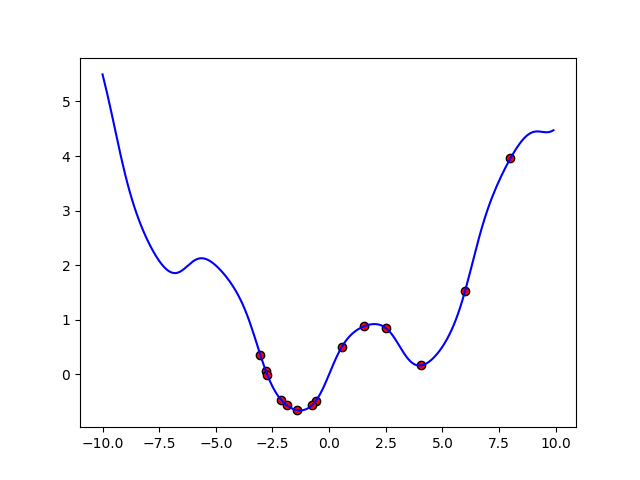

In [ ]:
x0 = 8
lr = 2
iterations = 15
points= []

x_range = torch.arange(-10, 10, 0.1)
x = torch.Tensor([x0]).requires_grad_()
optimizer = torch.optim.Adam([x], lr=lr)

for i in range(iterations):
    optimizer.zero_grad()
    f = function_2d(x)
    f.backward()
    points += [(x.item(), f.item())]
    optimizer.step()

anim_2d(x_range, function_2d, points, 400)

##Scheduler

- Scheduler는 우리가 아는 Learning Rate를 수정하는 방법이다.

예시를 먼저 보자.

In [ ]:
def f(x):
    return x.abs() * 5

In [ ]:
x0 = 8
lr = 0.5
iterations = 150

x = torch.Tensor([x0]).requires_grad_()
y_target = torch.Tensor([0])

optimizer = optim.SGD([x], lr=lr)
loss_function = torch.nn.L1Loss()
scheduler = optim.lr_scheduler.ExponentialLR(optimizer, 0.8)

for i in range(iterations):
    optimizer.zero_grad()
    y = f(x)
    loss = loss_function(y, y_target)
    loss.backward()
    optimizer.step()
    scheduler.step()
    print(y.data, " | lr : ", optimizer.param_groups[0]['lr'])

tensor([40.])  | lr :  0.4
tensor([27.500])  | lr :  0.32000000000000006
tensor([17.500])  | lr :  0.25600000000000006
tensor([9.500])  | lr :  0.20480000000000007
tensor([3.100])  | lr :  0.16384000000000007
tensor([2.020])  | lr :  0.13107200000000005
tensor([2.076])  | lr :  0.10485760000000005
tensor([1.201])  | lr :  0.08388608000000004
tensor([1.421])  | lr :  0.06710886400000003
tensor([0.677])  | lr :  0.05368709120000003
tensor([1.001])  | lr :  0.042949672960000025
tensor([0.341])  | lr :  0.03435973836800002
tensor([0.733])  | lr :  0.027487790694400018
tensor([0.126])  | lr :  0.021990232555520017
tensor([0.561])  | lr :  0.017592186044416015
tensor([0.011])  | lr :  0.014073748835532814
tensor([0.429])  | lr :  0.011258999068426251
tensor([0.077])  | lr :  0.009007199254741001
tensor([0.205])  | lr :  0.007205759403792801
tensor([0.020])  | lr :  0.0057646075230342415
tensor([0.160])  | lr :  0.0046116860184273935
tensor([0.016])  | lr :  0.003689348814741915
tensor([0.100

### Scheduler의 종류
- LambdaLR : 초기 Learning Rate에 Lambda 표현식으로 작성한 함수의 결과로 나온 값을 곱해서 Learning Rate 사용

 예시)

 scheduler = optim.lr_scheduler.LambdaLR(optimizer=optimizer, lr_lambda=lambda epoch: 0.95 ** epoch)
 일 때,

  $LR = 0.95^{epoch}$

- StepLR : Step마다 gamma의 비율로 감소

 예시) step_size = 10, gamma = 0.95일 때,

 $LR = 0.95^{1 + \lfloor \frac{epoch}{10} \rfloor}$

- MultiStepLR : Learning Rate가 감소하는 특정 Epoch를 지정

 예시)

 scheduler = optim.lr_scheduler.MultiStepLR(optimizer, milestones=[30,80], gamma=0.5)

 epoch가 30, 80일 때, Learning Rate가 1/2로 감소

- ReduceLROnPlateau : 학습 성능이 향상되지 않을때 Learning Rate를 변경. 따라서 Step에 loss를 입력해줘야 한다.

 예시)

 scheduler = ReduceLROnPlateau(optimizer, 'min')

 optimizer의 loss가 최소일 때 성능 개선으로 보며 loss가 감소하지 않을경우 개선되지 않은것으로 판단.

In [2]:
import numpy as np # 선형대수 모듈
import matplotlib.pyplot as plt # 시각화 모듈
import torch # 파이토치
import torch.nn as nn # PyTorch의 모듈을 모아놓은 것. from~~이 아닌 저렇게 임포트를 하는 것이 거의 관습이라고 한다.
import torch.nn.functional as F # torch.nn 중에서 자주 쓰는 함수를 F로 임포트.
import torch.nn.init as init # 초기화 관련 모듈
import torchvision # TorchVision 임포트
from torchvision import transforms, datasets # 데이터를 다루기 위한 TorchVision 내의 Transforms와 datasets를 따로 임포트
import torch.optim as optim

BATCH_SIZE = 32
EPOCHS = 30

train_dataset = datasets.MNIST(
    root="../data/MNIST",
    train=True,
    download=True,
    transform=transforms.ToTensor()
)
test_dataset = datasets.MNIST(
    root="../data/MNIST",
    train=False,
    download=True,
    transform=transforms.ToTensor()
)
train_loader = torch.utils.data.DataLoader(
    dataset=train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)
test_loader = torch.utils.data.DataLoader(
    dataset=test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class MLP(nn.Module):
    def __init__(self):
        super(MLP, self).__init__()
        self.fc1 = nn.Linear(28 * 28, 512)
        self.fc2 = nn.Linear(512, 256)
        self.fc3 = nn.Linear(256, 10)
        self.dropout_prob = 0.5 # 50%의 노드에 대한 가중치 계산을 하지 않기 위한 설정
        self.batch_norm1 = nn.BatchNorm1d(512) # 1dimension이기 때문에 BatchNorm1d를 사용함.
        self.batch_norm2 = nn.BatchNorm1d(256)

    def forward(self, x):
        x = x.view(-1, 28 * 28)
        print(x.shape)
        print(self.fc1.weight.shape)
        x = self.fc1(x)
        x = self.batch_norm1(x)
        x = F.relu(x) # sigmoid(x)
        x = F.dropout(x, training=self.training, p=self.dropout_prob)
        x = self.fc2(x)
        x = self.batch_norm2(x)
        x = F.relu(x) # sigmoid(x)
        x = F.dropout(x, training=self.training, p=self.dropout_prob)
        x = self.fc3(x)
        x = F.log_softmax(x, dim=1)
        return x

model = MLP()

loss_fn  = nn.CrossEntropyLoss()
# optimizer
optimizer = optim.Adam(model.parameters(), lr=0.001)
scheduler = optim.lr_scheduler.MultiplicativeLR(optimizer=optimizer,
                                                lr_lambda=lambda epoch: 0.7 ** epoch)
#scheduler

TestLosses = []
LearningRates = []


epochs=20
model
for epoch in range(epochs):

  model.train()
  print('epoch : ' + str(epoch) + ', learning rate : ' + str(optimizer.param_groups[0]['lr']))
  for batch_idx, (image, label) in enumerate(train_loader):
      image = image
      label = label
      optimizer.zero_grad()
      output = model(image)
      loss = loss_fn(output, label)
      loss.backward()
      optimizer.step()

  model.eval()

  test_loss = 0
  for batch_idx, (image, label) in enumerate(test_loader):
      image = image
      label = label
      output = model(image)
      test_loss += loss_fn(output, label).item()

  test_loss = test_loss / len(test_loader.dataset)
  TestLosses.append(test_loss)
  LearningRates.append(optimizer.param_groups[0]['lr'])
  print('test loss : ' + str(test_loss))
  scheduler.step()

epoch : 0, learning rate : 0.001
torch.Size([32, 784])
torch.Size([512, 784])
torch.Size([32, 784])
torch.Size([512, 784])
torch.Size([32, 784])
torch.Size([512, 784])
torch.Size([32, 784])
torch.Size([512, 784])
torch.Size([32, 784])
torch.Size([512, 784])
torch.Size([32, 784])
torch.Size([512, 784])
torch.Size([32, 784])
torch.Size([512, 784])
torch.Size([32, 784])
torch.Size([512, 784])
torch.Size([32, 784])
torch.Size([512, 784])
torch.Size([32, 784])
torch.Size([512, 784])
torch.Size([32, 784])
torch.Size([512, 784])
torch.Size([32, 784])
torch.Size([512, 784])
torch.Size([32, 784])
torch.Size([512, 784])
torch.Size([32, 784])
torch.Size([512, 784])
torch.Size([32, 784])
torch.Size([512, 784])
torch.Size([32, 784])
torch.Size([512, 784])
torch.Size([32, 784])
torch.Size([512, 784])
torch.Size([32, 784])
torch.Size([512, 784])
torch.Size([32, 784])
torch.Size([512, 784])
torch.Size([32, 784])
torch.Size([512, 784])
torch.Size([32, 784])
torch.Size([512, 784])
torch.Size([32, 784])


KeyboardInterrupt: ignored

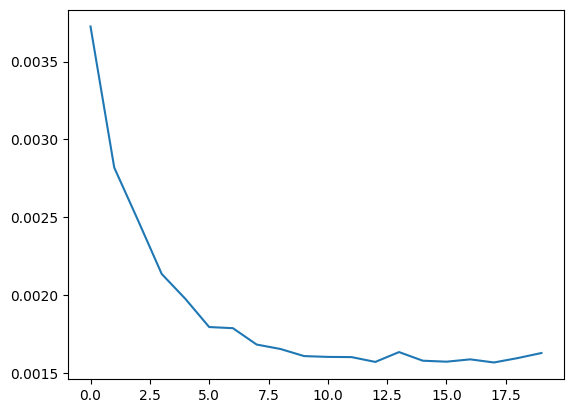

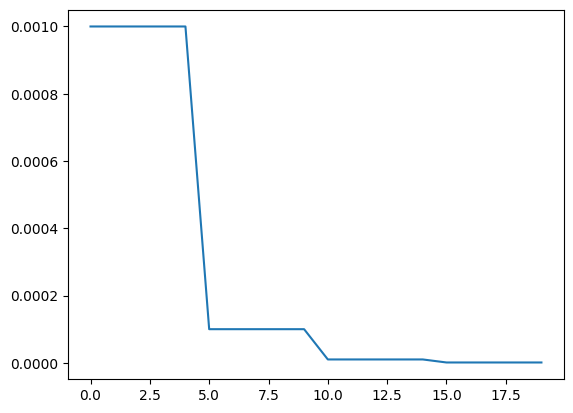

In [ ]:

from matplotlib import pyplot as plt

plt.figure()
plt.plot(TestLosses)
plt.figure()
plt.plot(LearningRates)

## 실습 !!!
- ReduceLROnPlateau, Adam Optimizer일 때 학습 결과는 같이 확인해보았다.
- 한번 다양한 Scheduler를 적용하며 결과를 확인해보자!

In [ ]:
# 힌트
# Scheduler 사용법
scheduler = optim.lr_scheduler.LambdaLR(optimizer=optimizer,
                                        lr_lambda=lambda epoch: 0.95 ** epoch)
scheduler = optim.lr_scheduler.MultiplicativeLR(optimizer=optimizer,
                                                lr_lambda=lambda epoch: 0.95 ** epoch)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.5)
scheduler = optim.lr_scheduler.MultiStepLR(optimizer, milestones=[30,80], gamma=0.5)
scheduler = optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.5)
scheduler = ReduceLROnPlateau(optimizer, 'min')

# 2교시 : RCNN, Fast-RCNN, Faster-RCNN

## Object Detection이란??
- 이미지상에 존재하는 객체 주변에 Bounding Box 생성
- 객체가 존재하는 정확한 영역은 알 수 없지만, 대략적인 위치 확인과 숫자 확인이 가능
- 객체 숫자 카운팅, 거리측정, 속도측정 등 다양한 활용이 가능하며 객체 세밀 분석을 위한 영역 추출에 사용 가능

![](https://images.velog.io/images/tataki26/post/0c67f497-de85-4751-9654-1485d71e083c/detection.png)

## 2013년부터 발전해온 알고리즘 RCNN
- 현재 가장 좋은 Detection 알고리즘 시리즈는 YOLO
- YOLO를 보기전 RCNN 시리즈를 공부해보자

(1) RCNN

(2) Fast-RCNN

(3) Faster-RCNN

## RCNN(Resion based Convolutional Neural Network) 시리즈의 기본 구조
- Propose Region : 전체 이미지에서 가장 객체가 있을법한 영역을 추천
- Feature Extracte : 추천받은 영역의 특징점을 추출
- Classifier : 객체를 인식하고 정확도 확인
- Non-Maximum Suppression : 중복되는 박스를 제거

## RCNN 시리즈

### RCNN
- RCNN 시리즈의 선구자
- 전통적인 이미지 처리 방식과 딥러닝 기반 방식을 혼합한 네트워크
- Selective search 알고리즘(픽셀 유사도 기반 클러스터링 및 구분)으로 2000개의 영역 추천
- CNN 기반 관심영역 feature 추출
- SVM(Support Vector Machine) 기반 객체 구분
- SVM, CNN, Selective search 알고리즘 혼합 사용으로 계산이 분할되어 한번에 학습되지 않음
- 추천영역을 2000로 고정하고 각각 CNN에 입력하여 연산시간이 오래걸림
![](https://wikidocs.net/images/page/136494/rcnn_3.png)

출처 : https://wikidocs.net/148633


### Fast-RCNN
- RCNN에서 문제를 해결해 빠른속도로 동작 가능한 Object Detection 알고리즘
- RCNN의 문제였던 2000번의 CNN 동작과, 한번에 학습이 불가능한 문제를 해결
![](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FIiNzk%2FbtqA8iSURGO%2F8F29HIsdwxAd6kMUnuKuu1%2Fimg.png)

##### ROI Pooling
- 기존에 문제 되던 2000번의 CNN을 보완하기 위해 ROI-Pooling 추가
- 입력 이미지를 CNN 네트워크에 통과시켜 7x7 feature map을 생성
- 생성된 feature map에 Selective search 알고리즘의 출력 결과를 Projection
- Projection 된 영역을 미리 설정한 Grid(이미지 분할영역)으로 분할
- Grid 마다 Maxpooling을 적용해 ROI 영역을 feature vector로 변환하여 FC-layer의 입력으로 사용

##### End-to-End Network
- ROI Pooling의 영향으로 별도로 동작하던 네트워크가 하나로 병합
- 네트워크의 시작부터 끝까지 한번에 연결된 End-to-End Network 구성

##### 단점
- 처음 동작하는 Selective search 알고리즘은 네트워크 동작이 아님
- 네트워크 외부에서 동작하는 부분의 존재로 속도의 botteneck이 존재

![](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FoHUnL%2FbtqBc5dG1ix%2F9EWJiCVhnHoTFZQTtCckYK%2Fimg.png)

출처 : https://ganghee-lee.tistory.com/36

### Faster-RCNN
- 이름에서 알 수 있듯 조금 '더' 빠른 Object Detection Algorithm
- Fast-RCNN에서 botteneck이었던 Selective search 알고리즘을 수정
- 모든 단계를 네트워크 기반으로 진행하여 한번에 **학습가능☆**
- 시리즈의 이전 방식들에 비해 속도를 크게 개선
![](https://miro.medium.com/v2/resize:fit:4800/format:webp/1*tTqg3W165itg-LVRFxHJfA.jpeg)

#### Region Proposal Network
- 시리즈의 이전 방식들은 모두 Seletive search 알고리즘을 통해 객체 예상 위치를 출력했다.
- Region Proposal Network는 Faster RCNN에서 제안된 방식으로 객체 예상 위치를 뽑기 위해 적용
- 입력된 이미지에서 8 x 8 x 512의 feature map을 뽑음
- 원본 이미지가 800 x 800이라 할때, 1개의 픽셀은 100x100의 영역을 대변
- feagture map에 3x3 conv net을 적용(패딩을 통해 해상도 유지).
- 여기에 1x1 conv net을 적용하여 총 2x9의 채널을 재생성 (8x8x512 -> 8x8x2x9) 2:오브젝트 인지 아닌지를 학습, 9:앵커(그리드 기반 영역)
- 또한 1x1 covn net을 같이 적용해 총 4x9의 채널 재생성 (8x8x512 -> 8x8x4x9)
4x9 : Bounding box regression 4는 Box cx, cy, width, height, 9는 앵커
- 생성된 앵커에 객체가 있고 Classification 값이 큰 순서로 추출
![](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2Fo7PTm%2FbtqAXir1rPy%2FVbzsfY9JMY9N3ixCe3zxb0%2Fimg.png)

#### 단점
- Resion Proposal Network로 Box를 먼저 구하고 Classifier로 객체를 구분하는 2단계 구성으로 속도 측면의 한계

   => Box 출력과 Classifier를 동시에 동작하는 yolo를 만들자

## 한번 Faster-RCNN의 코드를 봐보자!
https://github.com/jwyang/faster-rcnn.pytorch/tree/master/lib/model
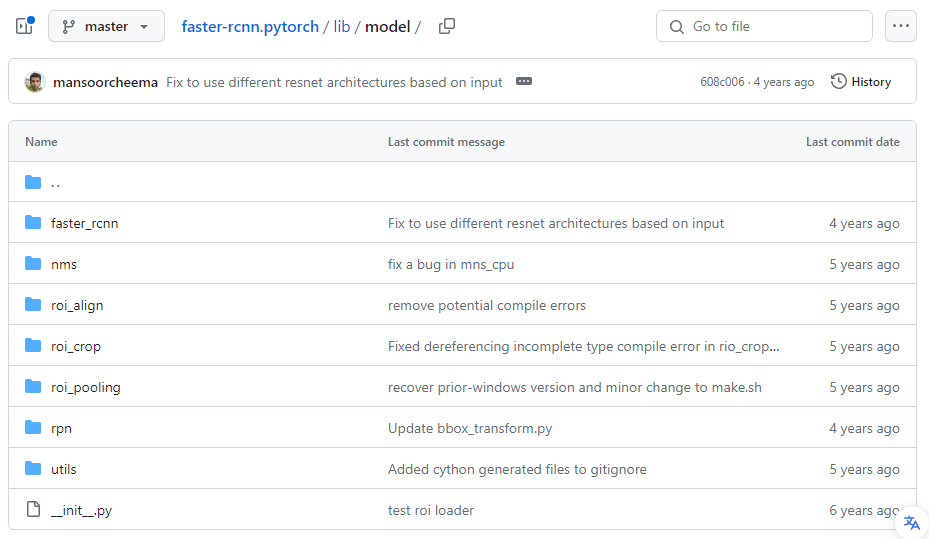

- 링크로 들어가면 Faster RCNN의 코드를 부분부분으로 친절하게 나눠 설명함
- 모든 코드가 깔끔하게 정리되어 있어 편하게 볼 수 있음
- 다만 코렙 파일이 아니기에 .py를 돌려야 하므로 별도의 환경세팅이 필요하다









## 솔직히 저런 코드는 보고싶지 않다.
- 다행히 TorchVision 패키지에 사전에 정의된 Faster-RCNN의 함수가 있다
- 한번 TorchVision을 통해 사용해보자

### 패키지 로드

In [ ]:
!pip install imgaug --upgrade     #image augmentation을 위해 필요
import torch      #pytorch
import torch.nn as nn     #pytorch network
from torch.utils.data import Dataset, DataLoader      #pytorch dataset
from torch.utils.tensorboard import SummaryWriter     #tensorboard
import torchvision      #torchvision
import torch.optim as optim     #pytorch optimizer
import numpy as np      #numpy
import matplotlib.pyplot as plt     #matplotlib(이미지 표시를 위해 필요)
from collections import OrderedDict     #python라이브러리 (라벨 dictionary를 만들 때 필요)
import os     #os
import xml.etree.ElementTree as Et      #Pascal xml을 읽어올 때 필요
from xml.etree.ElementTree import Element, ElementTree
import cv2      #opencv (box 그리기를 할 때 필요)
from PIL import Image     #PILLOW (이미지 읽기)
import time     #time
import imgaug as ia     #imgaug
from imgaug import augmenters as iaa
from torchvision import transforms      #torchvision transform
#GPU연결
if torch.cuda.is_available():
  device = torch.device('cuda:0')
else:
  device = torch.device('cpu')
print(device)

cpu


### 데이터셋 준비

In [ ]:
if not os.path.isfile("/content/voc_train_val2012_tar"):
  !cp "/content/drive/MyDrive/Faster_RCNN/VOCtrainval_11-May-2012.tar" "/content/voc_train_val2012_tar"
  ! tar -xf "/content/voc_train_val2012_tar"

cp: cannot stat '/content/drive/MyDrive/Faster_RCNN/VOCtrainval_11-May-2012.tar': No such file or directory
tar: /content/voc_train_val2012_tar: Cannot open: No such file or directory
tar: Error is not recoverable: exiting now


### 데이터셋 라벨 로드 및 읽기

In [ ]:
def xml_parser(xml_path):
  xml_path = xml_path
  xml = open(xml_path, "r")
  tree = Et.parse(xml)
  root = tree.getroot()
  size = root.find("size")
  file_name = root.find("filename").text
  object_name = []
  bbox = []
  objects = root.findall("object")
  for _object in objects:
      name = _object.find("name").text
      object_name.append(name)
      bndbox = _object.find("bndbox")
      one_bbox = []
      xmin = bndbox.find("xmin").text
      one_bbox.append(int(float(xmin)))
      ymin = bndbox.find("ymin").text
      one_bbox.append(int(float(ymin)))
      xmax = bndbox.find("xmax").text
      one_bbox.append(int(float(xmax)))
      ymax = bndbox.find("ymax").text
      one_bbox.append(int(float(ymax)))
      bbox.append(one_bbox)
  return file_name, object_name, bbox

### 이미지에 박스그리기

In [ ]:
def makeBox(voc_im,bbox,objects):
  image = voc_im.copy()
  for i in range(len(objects)):
    cv2.rectangle(image,(int(bbox[i][0]),int(bbox[i][1])),(int(bbox[i][2]),int(bbox[i][3])),color = (0,255,0),thickness = 1)
    cv2.putText(image, objects[i], (int(bbox[i][0]), int(bbox[i][1])-10), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0,255,0), 2) # 크기, 색, 굵기
  return image

### 라벨 집합만들기

In [ ]:
xml_list = os.listdir("/content/VOCdevkit/VOC2012/Annotations")
xml_list.sort()

label_set = set()

for i in range(len(xml_list)):
  xml_path = "/content/VOCdevkit/VOC2012/Annotations/"+str(xml_list[i])
  file_name, object_name, bbox = xml_parser(xml_path)
  for name in object_name:
    label_set.add(name)

label_set = sorted(list(label_set))

label_dic = {}
for i, key in enumerate(label_set):
  label_dic[key] = (i+1)


### 데이터셋 정의

In [ ]:
class Pascal_Voc(Dataset):

  def __init__(self,xml_list,len_data):

    self.xml_list = xml_list
    self.len_data = len_data
    self.to_tensor = transforms.ToTensor()
    self.flip = iaa.Fliplr(0.5)
    self.resize = iaa.Resize({"shorter-side": 600, "longer-side": "keep-aspect-ratio"})

  def __len__(self):
    return self.len_data

  def __getitem__(self, idx):

    xml_path = "/content/VOCdevkit/VOC2012/Annotations/"+str(xml_list[idx])

    file_name, object_name, bbox = xml_parser(xml_path)
    image_path = "/content/VOCdevkit/VOC2012/JPEGImages/"+str(file_name)
    image = Image.open(image_path).convert("RGB")
    image = np.array(image)

    image, bbox = self.flip(image = image, bounding_boxes = np.array([bbox]))
    image, bbox = self.resize(image = image,bounding_boxes = bbox)
    bbox = bbox.squeeze(0).tolist()
    image = self.to_tensor(image)

    targets = []
    d = {}
    d['boxes'] = torch.tensor(bbox,device=device)
    d['labels'] = torch.tensor([label_dic[x] for x in object_name],dtype=torch.int64,device = device)
    targets.append(d)

    return image, targets

### 모델 정의

In [ ]:
backbone = torchvision.models.vgg16(pretrained=True).features[:-1]
backbone_out = 512
backbone.out_channels = backbone_out

anchor_generator = torchvision.models.detection.rpn.AnchorGenerator(sizes=((128, 256, 512),),aspect_ratios=((0.5, 1.0, 2.0),))

resolution = 7
roi_pooler = torchvision.ops.MultiScaleRoIAlign(featmap_names=['0'], output_size=resolution, sampling_ratio=2)

box_head = torchvision.models.detection.faster_rcnn.TwoMLPHead(in_channels= backbone_out*(resolution**2),representation_size=4096)
box_predictor = torchvision.models.detection.faster_rcnn.FastRCNNPredictor(4096,21) #21개 class

model = torchvision.models.detection.FasterRCNN(backbone, num_classes=None,
                   min_size = 600, max_size = 1000,
                   rpn_anchor_generator=anchor_generator,
                   rpn_pre_nms_top_n_train = 6000, rpn_pre_nms_top_n_test = 6000,
                   rpn_post_nms_top_n_train=2000, rpn_post_nms_top_n_test=300,
                   rpn_nms_thresh=0.7,rpn_fg_iou_thresh=0.7,  rpn_bg_iou_thresh=0.3,
                   rpn_batch_size_per_image=256, rpn_positive_fraction=0.5,
                   box_roi_pool=roi_pooler, box_head = box_head, box_predictor = box_predictor,
                   box_score_thresh=0.05, box_nms_thresh=0.7,box_detections_per_img=300,
                   box_fg_iou_thresh=0.5, box_bg_iou_thresh=0.5,
                   box_batch_size_per_image=128, box_positive_fraction=0.25
                 )
#roi head 있으면 num_class = None으로 함

for param in model.rpn.parameters():
  torch.nn.init.normal_(param,mean = 0.0, std=0.01)

for name, param in model.roi_heads.named_parameters():
  if "bbox_pred" in name:
    torch.nn.init.normal_(param,mean = 0.0, std=0.001)
  elif "weight" in name:
    torch.nn.init.normal_(param,mean = 0.0, std=0.01)
  if "bias" in name:
    torch.nn.init.zeros_(param)

### Training

In [ ]:
writer = SummaryWriter("/content/drive/MyDrive/Faster_RCNN/runs/Faster_RCNN")
%load_ext tensorboard
%tensorboard --logdir="/content/drive/MyDrive/Faster_RCNN/runs"

### 로스 정의

In [ ]:
def Total_Loss(loss):
  loss_objectness = loss['loss_objectness']
  loss_rpn_box_reg = loss['loss_rpn_box_reg']
  loss_classifier = loss['loss_classifier']
  loss_box_reg = loss['loss_box_reg']

  rpn_total = loss_objectness + 10*loss_rpn_box_reg
  fast_rcnn_total = loss_classifier + 1*loss_box_reg

  total_loss = rpn_total + fast_rcnn_total

  return total_loss

### 실제 학습

In [ ]:
total_epoch = 40

len_data = 15000
term = 1000

loss_sum = 0

model.to(device)

optimizer = torch.optim.SGD(params = model.parameters(),lr = 0.001, momentum = 0.9, weight_decay=0.0005)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,total_epoch,eta_min=0.00001)

try:
  check_point = torch.load("/content/drive/My Drive/Faster_RCNN/Check_point.pth")
  start_epoch = check_point['epoch']
  start_idx = check_point['iter']
  model.load_state_dict(check_point['state_dict'])
  optimizer.load_state_dict(check_point['optimizer'])
  scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,total_epoch,eta_min=0.00001,last_epoch = start_epoch)
  scheduler.load_state_dict(check_point['scheduler'])

  if start_idx == len_data:
    start_idx = 0
    start_epoch = start_epoch + 1

except:
  print("check point load error!")
  start_epoch = 0
  start_idx = 0

print("start_epoch = {} , start_idx = {}".format(start_epoch,start_idx))

print("Training Start")
model.train()
start = time.time()

for epoch in range(start_epoch,total_epoch):

  writer.add_scalar('Learning Rate',scheduler.get_last_lr()[0], epoch)

  dataset = Pascal_Voc(xml_list[:len_data],len_data - start_idx)
  dataloader = DataLoader(dataset,shuffle=True)

  for i, (image,targets)in enumerate(dataloader,start_idx):

    optimizer.zero_grad()

    targets[0]['boxes'].squeeze_(0)
    targets[0]['labels'].squeeze_(0)

    loss = model(image.to(device),targets)
    total_loss = Total_Loss(loss)
    loss_sum += total_loss

    if (i+1) % term == 0:
      end = time.time()
      print("Epoch {} | Iter {} | Loss: {} | Duration: {} min".format(epoch,(i+1),(loss_sum/term).item(),int((end-start)/60)))
      writer.add_scalar('Training Loss',loss_sum / term, epoch * len_data + i)

      state = {
        'epoch': epoch,
        'iter' : i+1,
        'state_dict': model.state_dict(),
        'optimizer' : optimizer.state_dict(),
        'scheduler': scheduler.state_dict()
      }
      torch.save(state,"/content/drive/My Drive/Faster_RCNN/Check_point.pth")

      loss_sum = 0
      start = time.time()

    total_loss.backward()
    optimizer.step()

  start_idx = 0
  scheduler.step()

  state = {
      'epoch': epoch,
      'iter' : i+1,
      'state_dict': model.state_dict(),
      'optimizer' : optimizer.state_dict(),
      'scheduler': scheduler.state_dict()
    }
  torch.save(state,"/content/drive/My Drive/Faster_RCNN/Check_point.pth")

  if (epoch+1) % 10 == 0:
    torch.save(model.state_dict(),"/content/drive/My Drive/Faster_RCNN/Epoch{}.pth".format(epoch))

# 3교시 : You Only Look Once (YOLO)

## YOLO에 대해 들어보셨나요?
- YOLO 시리즈는 현존하는 Detection 알고리즘 중 최고의 시리즈
- 실제 Object Detection 기반 어플리케이션의 99.9999%가 YOLO를 기반으로 하고있다 해도 무방함
- Object Detection은 yolo 이전과 이후로 나눠진다!
- 실제 초기 연구진은 yolo v3까지 만들었고, 엄청난 성능으로 군사적 이용등이 두려워 v3에서 연구를 멈춤

  (하지만 전혀 무관한 연구진 2팀이 v10까지 만듬)

> https://medium.com/curg/you-only-look-once-%EB%8B%A4-%EB%8B%A8%EC%A7%80-%ED%95%9C-%EB%B2%88%EB%A7%8C-%EB%B3%B4%EC%95%98%EC%9D%84-%EB%BF%90%EC%9D%B4%EB%9D%BC%EA%B5%AC-bddc8e6238e2

## YOLO v1
![](https://images.velog.io/images/skhim520/post/e3390906-b8f6-454f-adbf-d40a35e407d3/image.png)
- YOLO 시리즈의 시작
- 이미지에서 S * S 그리드 출력(GoogLeNet 구조 기반)
- 각각의 grid cell 내에 B개의 bounding box와 각 객체일 확률을 나타내는 confidence score를 예측

  Confidence = Pr(object) * IOU(pred, truth)

- 따라서 각각의 그리드 마다 2개의 Box를 예측할 수 있으며 단 하나의 객체 종류를 예측할 수 있음


### 단점
- 하나의 그리드에서 하나의 객체만 추론할 수 있어 붙어있는 객체를 인식할 수 없음
- bounding box의 형태가 학습데이터에 포함되지 않았을때 인식 실패율이 높음

## YOLO v2

![](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2F95JBN%2FbtqTEM8lVmg%2FW2Fg2DNDUr6J2wfKoA5s3k%2Fimg.png)


- YOLO Network의 2번째 버전
- faster-rcnn에서 적용한 Ancker를 YOLO에 적용하여 grid에서 새로 탐지하지 않고 Ancker에서 수정하는 형태로 변경
- 다만 사전에 Ancker의 개수와 가로세로비를 고정하지않고 k-means-clustering 알고리즘을 통해 최적의 수를 계산
- Darknet-19 classification Network 적용으로 fc layer의 파라메터수 감소
- anchor box 기반 bounding box 예측은 학습 초기에 불안할 수 있어 sigmoid 함수와 별도의 수식을 적용


![](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FrY8Ua%2FbtqV2XmCUtW%2F15eavL05i7jPrYtBD1AIJ0%2Fimg.png)

![](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FYMU3b%2FbtqV0Eah13d%2FNEqXsZ0OaAe3uoqUl78wp0%2Fimg.png)


## YOLO v3
- Object Detection 알고리즘 YOLO의 기반 형태 완성형
- 이 논문을 기반으로 초기 연구진들은 연구 중단
- YOLO v2까지의 grid마다 softmax 형태로 출력하던 것을 **박스마다** 생성하여 Multi-Label classification이 가능
- fc 기반 FPN(Feature Pyramid Network)을 통해 물체의 크기 변화에 강인하게 네트워크 구성

![](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FbNkVM3%2FbtqXxdOyiFH%2FZdEsXc4xtwS6PV7zTSRuuK%2Fimg.png)

### FPN(Feature Pyramid Network)
- yolo의 기본 입력은 416x 416이다.
- 만약 입력 이미지에 차량의 픽셀이 10x10일 때, 그리드 사이즈가 13x13이면 어떻게 될까?
- 416/13 = 32 이므로 차량의 크기는 그리드 하나의 1/9밖에 되지 않는다.
- 그렇다고 작은 객체를 위해 그리드 사이즈를 40x40으로 하면, 정보 압축이 되지않아 구분을 못한다!
- FPN은 이를 보완하기 위해 다양한 사이즈의 정보를 **조합하여** 인식
- 52X52, 26,26, 13x13의 feature를 추출하고  작은 사이즈 feature를 up-sampling한 뒤 Concatenate!
- 여러 해상도의 결과를 모두 사용한 결과 추출가능

![](https://wikidocs.net/images/page/162976/FPN_10.jpeg)

##YOLO v3 코드
- 이론은 중요하지만 너무 어렵다.
- 한번 코드로 확인해보자
- 매우매우 중요한 코드이니 바닐라부터 같이 보자

#### 코드 구현체

##### 기본적인 Convolution Layer

In [ ]:
# basic conv layer
class BasicConv(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size, stride, padding):
        super().__init__()

        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size, stride, padding, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.LeakyReLU(0.1)
        )

    def forward(self, x):
        return self.conv(x)

##### Convoluition Layer to ResBlock

In [ ]:
# Residual block
class ResidualBlock(nn.Module):
    def __init__(self, channels):
        super().__init__()

        self.residual = nn.Sequential(
            BasicConv(channels, channels//2, 1, stride=1, padding=0),
            BasicConv(channels//2, channels, 3, stride=1, padding=1)
        )

        self.shortcut = nn.Sequential()

    def forward(self, x):
        x_shortcut = self.shortcut(x)
        x_residual = self.residual(x)

        return x_shortcut + x_residual

##### FPN Top-Down Layer

In [ ]:
# FPN의 Top_down layer
class Top_down(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.conv = nn.Sequential(
            BasicConv(in_channels, out_channels, 1, stride=1, padding=0),
            BasicConv(out_channels, out_channels*2, 3, stride=1, padding=1),
            BasicConv(out_channels*2, out_channels, 1, stride=1, padding=0),
            BasicConv(out_channels, out_channels*2, 3, stride=1, padding=1),
            BasicConv(out_channels*2, out_channels, 1, stride=1, padding=0)
        )

    def forward(self, x):
        return self.conv(x)

##### 추출된 각각의 Feature map이 통과하는 예측 네트워크

In [ ]:
# YOLO Layer는 13x13, 26x26, 52x52 피쳐맵에서 예측을 수행합니다.
class YOLOLayer(nn.Module):
    def __init__(self, channels, anchors, num_classes=20, img_dim=416):
        super().__init__()
        self.anchors = anchors # three anchors per YOLO Layer
        self.num_anchors = len(anchors) # 3
        self.num_classes = num_classes # VOC classes 20
        self.img_dim = img_dim # 입력 이미지 크기 416
        self.grid_size = 0

        # 예측을 수행하기 전, smooth conv layer 입니다.
        self.conv = nn.Sequential(
            BasicConv(channels, channels*2, 3, stride=1, padding=1),
            nn.Conv2d(channels*2, 75, 1, stride=1, padding=0)
        )

    def forward(self, x):
        x = self.conv(x)

        # prediction
        # x: batch, channels, W, H
        batch_size = x.size(0)
        grid_size = x.size(2) # S = 13 or 26 or 52
        device = x.device

        prediction = x.view(batch_size, self.num_anchors, self.num_classes + 5,
                            grid_size, grid_size) # shape = (batch, 3, 25, S, S)

        # shape change (batch, 3, 25, S, S) -> (batch, 3, S, S, 25)
        prediction = prediction.permute(0, 1, 3, 4, 2)
        prediction = prediction.contiguous()

        obj_score = torch.sigmoid(prediction[..., 4]) # Confidence: 1 if object, else 0
        pred_cls = torch.sigmoid(prediction[..., 5:]) # 바운딩 박스 좌표

        # grid_size 갱신
        if grid_size != self.grid_size:
            # grid_size를 갱신하고, transform_outputs 함수를 위해 anchor 박스를 전처리 합니다.
            self.compute_grid_offsets(grid_size, cuda=x.is_cuda)

        # calculate bounding box coordinates
        pred_boxes = self.transform_outputs(prediction)

        # output shape(batch, num_anchors x S x S, 25)
        # ex) at 13x13 -> [batch, 507, 25], at 26x26 -> [batch, 2028, 25], at 52x52 -> [batch, 8112, 25]
        # 최종적으로 YOLO는 10647개의 바운딩박스를 예측합니다.
        output = torch.cat((pred_boxes.view(batch_size, -1, 4),
                    obj_score.view(batch_size, -1, 1),
                    pred_cls.view(batch_size, -1, self.num_classes)), -1)
        return output


    # grid_size를 갱신하고, transform_outputs 함수를 위해 anchor 박스를 전처리 합니다.
    def compute_grid_offsets(self, grid_size, cuda=True):
        self.grid_size = grid_size # ex) 13, 26, 52
        self.stride = self.img_dim / self.grid_size

        # cell index 생성
        # transform_outputs 함수에서 바운딩 박스의 x, y좌표를 예측할 때 사용합니다.
        # 1, 1, S, S
        self.grid_x = torch.arange(grid_size, device=device).repeat(1, 1, grid_size, 1).type(torch.float32)
        # 1, 1, S, S
        self.grid_y = torch.arange(grid_size, device=device).repeat(1, 1, grid_size, 1).transpose(3,2).type(torch.float32)

        # anchors를 feature map 크기로 정규화, [0~1] 범위
        scaled_anchors = [(a_w / self.stride, a_h / self.stride) for a_w, a_h in self.anchors]
        # tensor로 변환
        self.scaled_anchors = torch.tensor(scaled_anchors, device=device)

        # transform_outputs 함수에서 바운딩 박스의 w, h를 예측할 때 사용합니다.
        # shape=(3,2) -> (1, 3, 1, 1)
        self.anchor_w = self.scaled_anchors[:, 0:1].view((1, self.num_anchors, 1, 1))
        self.anchor_h = self.scaled_anchors[:, 1:2].view((1, self.num_anchors, 1, 1))


    # 예측한 바운딩 박스 좌표를 계산하는 함수입니다.
    def transform_outputs(self, prediction):
        # prediction = (batch, num_anchors, S, S, coordinates + classes)
        device = prediction.device
        x = torch.sigmoid(prediction[..., 0]) # sigmoid(box x), 예측값을 sigmoid로 감싸서 [0~1] 범위
        y = torch.sigmoid(prediction[..., 1]) # sigmoid(box y), 예측값을 sigmoid로 감싸서 [0~1] 범위
        w = prediction[..., 2] # 예측한 바운딩 박스 너비
        h = prediction[..., 3] # 예측한 바운딩 박스 높이

        pred_boxes = torch.zeros_like(prediction[..., :4]).to(device)
        pred_boxes[..., 0] = x.data + self.grid_x # sigmoid(box x) + cell x 좌표
        pred_boxes[..., 1] = y.data + self.grid_y # sigmoid(box y) + cell y 좌표
        pred_boxes[..., 2] = torch.exp(w.data) * self.anchor_w
        pred_boxes[..., 3] = torch.exp(h.data) * self.anchor_h

        return pred_boxes * self.stride

##### 3개의 Feature map이 통과한 결과를 합치는 최종 구현체

In [ ]:
class DarkNet(nn.Module):
    def __init__(self, anchors, num_blocks=[1,2,8,8,4], num_classes=20):
        super().__init__()

        # DarkNet, feature extractor
        self.conv1 = BasicConv(3, 32, 3, stride=1, padding=1)             # 416x416
        self.res_block_1 = self._make_residual_block(64, num_blocks[0])   # 208x208
        self.res_block_2 = self._make_residual_block(128, num_blocks[1])  # 104x104
        self.res_block_3 = self._make_residual_block(256, num_blocks[2])  # 52x52, FPN lateral connection
        self.res_block_4 = self._make_residual_block(512, num_blocks[3])  # 26x26, FPN lateral connection
        self.res_block_5 = self._make_residual_block(1024, num_blocks[4]) # 13x13, Top layer

        # FPN Top down
        self.topdown_1 = Top_down(1024, 512)
        self.topdown_2 = Top_down(768, 256)
        self.topdown_3 = Top_down(384, 128)

        # FPN lateral connection
        # 차원 축소를 위해 사용합니다.
        self.lateral_1 = BasicConv(512, 256, 1, stride=1, padding=0)
        self.lateral_2 = BasicConv(256, 128, 1, stride=1, padding=0)

        # prediction, 13x13, 26x26, 52x52 피쳐맵에서 예측을 수행합니다.
        self.yolo_1 = YOLOLayer(512, anchors=anchors[2]) # 13x13
        self.yolo_2 = YOLOLayer(256, anchors=anchors[1]) # 26x26
        self.yolo_3 = YOLOLayer(128, anchors=anchors[0]) # 52x52

        self.upsample = nn.Upsample(scale_factor=2)


    def forward(self, x):
        # DarkNet, feature extractor
        x = self.conv1(x)
        c1 = self.res_block_1(x)
        c2 = self.res_block_2(c1)
        c3 = self.res_block_3(c2)
        c4 = self.res_block_4(c3)
        c5 = self.res_block_5(c4)

        # FPN Top-downm, Upsample and lateral connection
        p5 = self.topdown_1(c5)
        p4 = self.topdown_2(torch.cat((self.upsample(p5), self.lateral_1(c4)), 1))
        p3 = self.topdown_3(torch.cat((self.upsample(p4), self.lateral_2(c3)), 1))

        # prediction
        yolo_1 = self.yolo_1(p5) # 13x13
        yolo_2 = self.yolo_2(p4) # 26x25
        yolo_3 = self.yolo_3(p3) # 52x52

        return torch.cat((yolo_1, yolo_2, yolo_3), 1), [yolo_1, yolo_2, yolo_3]

    def _make_residual_block(self,in_channels, num_block):
        blocks = []
        # down sample
        blocks.append(BasicConv(in_channels//2, in_channels, 3, stride=2, padding=1))
        for i in range(num_block):
            blocks.append(ResidualBlock(in_channels))
        return nn.Sequential(*blocks)

##### Anchor 대비 비율로 출력되는 결과를 Bounding Box로 변환하는 코드

In [ ]:
anchors = [[(10,13),(16,30),(33,23)],[(30,61),(62,45),(59,119)],[(116,90),(156,198),(373,326)]]
x = torch.randn(1, 3, 416, 416).to(device)
with torch.no_grad():
    model = DarkNet(anchors).to(device)
    output_cat , output = model(x)
    print(output_cat.size())
    print(output[0].size(), output[1].size(), output[2].size())

### 다음으로 누군가 만들어든 코드를 불러와 직접 동작시켜보자!
- 아쉽게도 yolov3은 너무 오래된 버전이라 깔끔하게 업로드된 구현체가 없다.
- 대신 yolov5의 구현체를 가져와 테스트해보자.
- yolov5와 yolov3는 Darknet 기반 으로 구현한 네트워크를 CSP-Darknet으로 변경하고, 다양한 사이즈로 Network를 나눴다.
- 사실 CSP-Darknet은 별로 중요하지 않으니 그냥 같은 네트워크로 생각하자!

In [ ]:
!git clone https://github.com/ultralytics/yolov5  # clone

Cloning into 'yolov5'...
remote: Enumerating objects: 15966, done.
remote: Counting objects: 100% (86/86), done.
remote: Compressing objects: 100% (57/57), done.
remote: Total 15966 (delta 44), reused 55 (delta 29), pack-reused 15880
Receiving objects: 100% (15966/15966), 14.70 MiB | 19.30 MiB/s, done.
Resolving deltas: 100% (10943/10943), done.


In [ ]:
!pip install -r yolov5/requirements.txt  # install

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 188.8/188.8 kB 3.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 616.3/616.3 kB 12.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.7/62.7 kB 5.4 MB/s eta 0:00:00


In [ ]:
!cd yolov5

In [ ]:

import torch
#print(torch.__version__)
model = torch.hub.load("ultralytics/yolov5", "yolov5s")

/usr/local/lib/python3.10/dist-packages/torch/hub.py:286: UserWarning: You are about to download and run code from an untrusted repository. In a future release, this won't be allowed. To add the repository to your trusted list, change the command to {calling_fn}(..., trust_repo=False) and a command prompt will appear asking for an explicit confirmation of trust, or load(..., trust_repo=True), which will assume that the prompt is to be answered with 'yes'. You can also use load(..., trust_repo='check') which will only prompt for confirmation if the repo is not already trusted. This will eventually be the default behaviour
  warnings.warn(
Downloading: "https://github.com/ultralytics/yolov5/zipball/master" to /root/.cache/torch/hub/master.zip
YOLOv5 🚀 2023-9-11 Python-3.10.12 torch-2.0.1+cu118 CPU

100%|██████████| 14.1M/14.1M [00:00<00:00, 21.1MB/s]

Fusing layers... 
YOLOv5s summary: 213 layers, 7225885 parameters, 0 gradients
Adding AutoShape... 


In [ ]:
import os
import time
from PIL import Image, ImageDraw
import cv2
import numpy as np

# 다운받을 이미지 url
url = "https://content.gallup.com/origin/gallupinc/GallupSpaces/Production/Cms/TGBCMS/iy1ex3cookmf9cme5qlnxa.jpg"

# time check
start = time.time()

# curl 요청
os.system("curl " + url + " > test.jpg")

# 이미지 다운로드 시간 체크
print(time.time() - start)

# 저장 된 이미지 확인
img = Image.open("test.jpg")

0.2517518997192383


In [ ]:
results = model(img)
results.print()
results.show()

Output hidden; open in https://colab.research.google.com to view.

# 4교시 : 모델 저장과 불러오기

## 혹시 코랩을 사용하다 이런적 없나요?
- 런타임이 끝났으니 다시 시작하세요
- 실수로 코랩 탭을 꺼버렸어요
- 잘 학습중이던 코드가 버그(기타등등)으로 멈춰버렸어요.

## 우리는 매번 새로 학습할 수 없다.
- 학습은 네트워크 복잡도에 따라 10초 이내에서 몇달까지 걸릴수 있다.
- 매번 새로 학습해서 사용하기엔 너무너무 긴 시간이 걸린다!
- 사용전에 매번 새로 학습할 수 없으니 학습된 결과를 **저장** 해야만 한다!!

## 다양한 저장 방법을 알아보자
- pickle
- torch.save(.pt, pbtxt)
- SafeTensor

테스트를 위해 1교시때 정의한 MNIST MLP를 불러와서 사용하자!

In [ ]:
import numpy as np # 선형대수 모듈
import matplotlib.pyplot as plt # 시각화 모듈
import torch # 파이토치
import torch.nn as nn # PyTorch의 모듈을 모아놓은 것. from~~이 아닌 저렇게 임포트를 하는 것이 거의 관습이라고 한다.
import torch.nn.functional as F # torch.nn 중에서 자주 쓰는 함수를 F로 임포트.
import torch.nn.init as init # 초기화 관련 모듈
import torchvision # TorchVision 임포트
from torchvision import transforms, datasets # 데이터를 다루기 위한 TorchVision 내의 Transforms와 datasets를 따로 임포트
import torch.optim as optim

BATCH_SIZE = 32
EPOCHS = 30

train_dataset = datasets.MNIST(
    root="../data/MNIST",
    train=True,
    download=True,
    transform=transforms.ToTensor()
)
test_dataset = datasets.MNIST(
    root="../data/MNIST",
    train=False,
    download=True,
    transform=transforms.ToTensor()
)
train_loader = torch.utils.data.DataLoader(
    dataset=train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)
test_loader = torch.utils.data.DataLoader(
    dataset=test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class MLP(nn.Module):
    def __init__(self):
        super(MLP, self).__init__()
        self.fc1 = nn.Linear(28 * 28, 512)
        self.fc2 = nn.Linear(512, 256)
        self.fc3 = nn.Linear(256, 10)
        self.dropout_prob = 0.5 # 50%의 노드에 대한 가중치 계산을 하지 않기 위한 설정
        self.batch_norm1 = nn.BatchNorm1d(512) # 1dimension이기 때문에 BatchNorm1d를 사용함.
        self.batch_norm2 = nn.BatchNorm1d(256)


    def forward(self, x):
        x = x.view(-1, 28 * 28)
        x = self.fc1(x)
        x = self.batch_norm1(x) #1d BN
        x = F.relu(x) # sigmoid(x)
        x = F.dropout(x, training=self.training, p=self.dropout_prob)
        x = self.fc2(x)
        x = self.batch_norm2(x)
        x = F.relu(x) # sigmoid(x)
        x = F.dropout(x, training=self.training, p=self.dropout_prob)
        x = self.fc3(x)
        x = F.log_softmax(x, dim=1)
        return x

model = MLP()

loss_fn  = nn.CrossEntropyLoss()
# optimizer
optimizer = optim.Adam(model.parameters(), lr=0.001)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.1)
#scheduler

TestLosses = []
LearningRates = []



model.cuda()
#model.to(device)


for epoch in range(EPOCHS):

  model.train()
  print('epoch : ' + str(epoch) + ', learning rate : ' + str(optimizer.param_groups[0]['lr']))
  for batch_idx, (image, label) in enumerate(train_loader):
      image = image.cuda()
      label = label.cuda()
      optimizer.zero_grad()
      output = model(image)
      loss = loss_fn(output, label)
      loss.backward()
      optimizer.step()

  model.eval()
  test_loss = 0
  for batch_idx, (image, label) in enumerate(test_loader):
      image = image.cuda()
      label = label.cuda()
      output = model(image)
      test_loss += loss_fn(output, label).item()

  test_loss = test_loss / len(test_loader.dataset)
  TestLosses.append(test_loss)
  LearningRates.append(optimizer.param_groups[0]['lr'])
  print('test loss : ' + str(test_loss))
  scheduler.step()

epoch : 0, learning rate : 0.001
test loss : 0.0036100439874164293
epoch : 1, learning rate : 0.001
test loss : 0.002797251206042711
epoch : 2, learning rate : 0.001
test loss : 0.002363920692013926
epoch : 3, learning rate : 0.001
test loss : 0.0022643143014691304
epoch : 4, learning rate : 0.001
test loss : 0.0022523470000654923
epoch : 5, learning rate : 0.0001
test loss : 0.0019050237733907124
epoch : 6, learning rate : 0.0001
test loss : 0.0017983237387132248
epoch : 7, learning rate : 0.0001
test loss : 0.0017066725667260472
epoch : 8, learning rate : 0.0001
test loss : 0.0016755050371168182
epoch : 9, learning rate : 0.0001
test loss : 0.0016521726983082772
epoch : 10, learning rate : 1e-05
test loss : 0.0017039720557844704
epoch : 11, learning rate : 1e-05
test loss : 0.00165160507911678
epoch : 12, learning rate : 1e-05
test loss : 0.0016708064926919178
epoch : 13, learning rate : 1e-05
test loss : 0.0016682636807785456
epoch : 14, learning rate : 1e-05
test loss : 0.001631274

## 1) pickle
- pickle은 python의 모든 객체를 저장할 수 있다.
- python의 기본적인 값 저장 방법이므로 당연히 모델도 저장할 수 있음
### <단점>
 - 하지만 전문적으로 모델을 저장하기위한 방법이 아니다.
 - 심지어 저장한 순서대로 불러오기 때문에, 저장한 순서도 알아야만 한다.

### 한번 pickle을 직접 사용해보자

In [ ]:
import pickle
my_list = ['a','b','c']

## Save pickle
with open("data1.pickle","wb") as fw: # 파일을 열 수 있다면 열어서 fw로 기억
    pickle.dump(model, fw) # fw에 my_list를 저장한다.

with open("data2.pickle","wb") as fw1: # 파일을 열 수 있다면 열어서 fw로 기억
    pickle.dump(model, fw1) # fw1에 my_list를 저장한다.
    pickle.dump(my_list, fw1) # fw1에 your_list를 저장한다.

## Load pickle
with open("data1.pickle","rb") as fr: # 파일을 열 수 있다면 열어서 fr로 기억
    data = pickle.load(fr) # fr에서 값을 불러온다.
print(data)



with open("data2.pickle","rb") as fr1: # 파일을 열 수 있다면 열어서 fr로 기억
    d1 = pickle.load(fr1) # fr에서 값을 불러온다.
    d2 = pickle.load(fr1) # fr에서 값을 불러온다.
print(d1)
print(d2)
#['a', 'b', 'c']

NameError: ignored

### 모델을 기억하지 못한상태에서 테스트해보자
- 런타임 -> 런타임 다시시작
- 런타임 다시시작으로 메모리가 삭제된 후 모델 불러오는 코드를 다시 실행해보자

In [ ]:
import pickle
## Load pickle
with open("data1.pickle","rb") as fr:
    model_pickle = pickle.load(fr) # 모델 클래스에 대한 구현체가 없어 에러메세지가 나온다!!
print(model_pickle)

AttributeError: ignored

### 모델을 다시 정의해보고 실행해볼까요?

In [ ]:
import numpy as np # 선형대수 모듈
import matplotlib.pyplot as plt # 시각화 모듈
import torch # 파이토치
import torch.nn as nn # PyTorch의 모듈을 모아놓은 것. from~~이 아닌 저렇게 임포트를 하는 것이 거의 관습이라고 한다.
import torch.nn.functional as F # torch.nn 중에서 자주 쓰는 함수를 F로 임포트.
import torch.nn.init as init # 초기화 관련 모듈
import torchvision # TorchVision 임포트
from torchvision import transforms, datasets # 데이터를 다루기 위한 TorchVision 내의 Transforms와 datasets를 따로 임포트
import torch.optim as optim
import pickle

BATCH_SIZE = 32
EPOCHS = 30

train_dataset = datasets.MNIST(
    root="../data/MNIST",
    train=True,
    download=True,
    transform=transforms.ToTensor()
)
test_dataset = datasets.MNIST(
    root="../data/MNIST",
    train=False,
    download=True,
    transform=transforms.ToTensor()
)
train_loader = torch.utils.data.DataLoader(
    dataset=train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)
test_loader = torch.utils.data.DataLoader(
    dataset=test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class MLP(nn.Module):
    def __init__(self):
        super(MLP, self).__init__()
        self.fc1 = nn.Linear(28 * 28, 512)
        self.fc2 = nn.Linear(512, 256)
        self.fc3 = nn.Linear(256, 10)
        self.dropout_prob = 0.5 # 50%의 노드에 대한 가중치 계산을 하지 않기 위한 설정
        self.batch_norm1 = nn.BatchNorm1d(512) # 1dimension이기 때문에 BatchNorm1d를 사용함.
        self.batch_norm2 = nn.BatchNorm1d(256)

    def forward(self, x):
        x = x.view(-1, 28 * 28)
        x = self.fc1(x)
        x = self.batch_norm1(x)
        x = F.relu(x) # sigmoid(x)
        x = F.dropout(x, training=self.training, p=self.dropout_prob)
        x = self.fc2(x)
        x = self.batch_norm2(x)
        x = F.relu(x) # sigmoid(x)
        x = F.dropout(x, training=self.training, p=self.dropout_prob)
        x = self.fc3(x)
        x = F.log_softmax(x, dim=1)
        return x


with open("data1.pickle","rb") as fr: # 파일을 열 수 있다면 열어서 fr로 기억
    model_pickle = pickle.load(fr) # fr에서 값을 불러온다.
print(model_pickle)


EOFError: ignored

## 2) torch.save
- torch.save는 pytorch에서 네트워크를 저장하기위한 목적으로 제공하는 방법
- 네트워크 구조를 몰라도 불러와 사용할 수 있음
- 모델 디렉토리를 저장하는 방법과 state_dict으로 값만 저장하는 방법이 있음


### 한번 torch.save를 직접 사용해보자(state_dict 사용X)

In [ ]:
torch.save(model, 'model_weights.pth')

model_torch = torch.load('model_weights.pth')

print(model_torch)


MLP(
  (fc1): Linear(in_features=784, out_features=512, bias=True)
  (fc2): Linear(in_features=512, out_features=256, bias=True)
  (fc3): Linear(in_features=256, out_features=10, bias=True)
  (batch_norm1): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (batch_norm2): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
)


### 이번엔 torch.save에서 state_dict를 사용해볼까?

In [ ]:
torch.save(model.state_dict(), 'model_weights_dict.pth')

model_torch2 = MLP()

model.load_state_dict(torch.load('model_weights_dict.pth'))

<All keys matched successfully>

두개의 차이가 무엇일까요??

In [ ]:
import os

file_size_simple = os.path.getsize('model_weights.pth')
file_size_dict = os.path.getsize('model_weights_dict.pth')
print('File "file_size_simple" Size:', file_size_simple, 'bytes')
print('File "file_size_dict" Size:', file_size_dict, 'bytes')


File "file_size_simple" Size: 2162209 bytes
File "file_size_dict" Size: 2160827 bytes


### 두 방법의 차이점
- state_dict()을 사용하지 않을경우 optimizer와 epoch 등 모든 상태를 그대로 저장하기 때문에 용량이 더 많이 필요하다

 (실제 간단한 모델을 사용해서 그렇지 원래는 훨씬 큰 차이남(크게는 2~3배 정도))

### pickle 대비 장점
- 클래스를 이진수형태로 저장하지 않고 딕셔너리 형태로 바꿔 파라메터를 저장하기 때문에 python 버전 변경에 더 강인하다!

## 3)TorchScript


### 실제 테스트를 해보자!

In [ ]:
model_scripted = torch.jit.script(model)
model_scripted.save('model_scripted.pt')
model_script = torch.jit.load('model_scripted.pt')
print(model_script)

RecursiveScriptModule(
  original_name=MLP
  (fc1): RecursiveScriptModule(original_name=Linear)
  (fc2): RecursiveScriptModule(original_name=Linear)
  (fc3): RecursiveScriptModule(original_name=Linear)
  (batch_norm1): RecursiveScriptModule(original_name=BatchNorm1d)
  (batch_norm2): RecursiveScriptModule(original_name=BatchNorm1d)
)


### 한번 런타임을 재시작하고 테스트해봅시다!

In [ ]:
import numpy as np # 선형대수 모듈
import matplotlib.pyplot as plt # 시각화 모듈
import torch # 파이토치
import torch.nn as nn # PyTorch의 모듈을 모아놓은 것. from~~이 아닌 저렇게 임포트를 하는 것이 거의 관습이라고 한다.
import torch.nn.functional as F # torch.nn 중에서 자주 쓰는 함수를 F로 임포트.
import torch.nn.init as init # 초기화 관련 모듈
import torchvision # TorchVision 임포트
from torchvision import transforms, datasets # 데이터를 다루기 위한 TorchVision 내의 Transforms와 datasets를 따로 임포트
import torch.optim as optim

#model_scripted = torch.jit.script(model)
#model_scripted.save('model_scripted.pt')
model_script = torch.jit.load('model_scripted.pt')
print(model_script)

## 4) safetensor
- HugginFace가 주도적으로 개발하는 방식
- JSON 텐서와 바이너리 텐서 데이터로 구성
- 모델의 구조를 JSON 헤더에 저장해 별도의 파이썬 파일이 필요하지 않음
- 관리하기 쉽고 용량이 작음
- 읽고 쓰는 속도가 빠름

### Safetensor 설치

In [ ]:
!pip install safetensors

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 13.7 MB/s eta 0:00:00


### Safetensor 사용

In [ ]:
#import safetensors
from safetensors.torch import save_model, load_model

save_model(model, "model_safetensor.safetensors")
model_safe = MLP()
load_model(model_safe, "model_safetensor.safetensors")
print(model_safe)

MLP(
  (fc1): Linear(in_features=784, out_features=512, bias=True)
  (fc2): Linear(in_features=512, out_features=256, bias=True)
  (fc3): Linear(in_features=256, out_features=10, bias=True)
  (batch_norm1): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (batch_norm2): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
)


한번 실제 모델을 적용하며 학습하는 예시를 만들어보자!

In [ ]:
import numpy as np # 선형대수 모듈
import matplotlib.pyplot as plt # 시각화 모듈
import torch # 파이토치
import torch.nn as nn # PyTorch의 모듈을 모아놓은 것. from~~이 아닌 저렇게 임포트를 하는 것이 거의 관습이라고 한다.
import torch.nn.functional as F # torch.nn 중에서 자주 쓰는 함수를 F로 임포트.
import torch.nn.init as init # 초기화 관련 모듈
import torchvision # TorchVision 임포트
from torchvision import transforms, datasets # 데이터를 다루기 위한 TorchVision 내의 Transforms와 datasets를 따로 임포트
import torch.optim as optim

BATCH_SIZE = 32
EPOCHS = 30

train_dataset = datasets.MNIST(
    root="../data/MNIST",
    train=True,
    download=True,
    transform=transforms.ToTensor()
)
test_dataset = datasets.MNIST(
    root="../data/MNIST",
    train=False,
    download=True,
    transform=transforms.ToTensor()
)
train_loader = torch.utils.data.DataLoader(
    dataset=train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)
test_loader = torch.utils.data.DataLoader(
    dataset=test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class MLP(nn.Module):
    def __init__(self):
        super(MLP, self).__init__()
        self.fc1 = nn.Linear(28 * 28, 512)
        self.fc2 = nn.Linear(512, 256)
        self.fc3 = nn.Linear(256, 10)
        self.dropout_prob = 0.5 # 50%의 노드에 대한 가중치 계산을 하지 않기 위한 설정
        self.batch_norm1 = nn.BatchNorm1d(512) # 1dimension이기 때문에 BatchNorm1d를 사용함.
        self.batch_norm2 = nn.BatchNorm1d(256)

    def forward(self, x):
        x = x.view(-1, 28 * 28)
        x = self.fc1(x)
        x = self.batch_norm1(x)
        x = F.relu(x) # sigmoid(x)
        x = F.dropout(x, training=self.training, p=self.dropout_prob)
        x = self.fc2(x)
        x = self.batch_norm2(x)
        x = F.relu(x) # sigmoid(x)
        x = F.dropout(x, training=self.training, p=self.dropout_prob)
        x = self.fc3(x)
        x = F.log_softmax(x, dim=1)
        return x

model = MLP()

loss_fn  = nn.CrossEntropyLoss()
# optimizer
optimizer = optim.Adam(model.parameters(), lr=0.001)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.1)
#scheduler

TestLosses = []
LearningRates = []


epochs = 30
model.cuda()
for epoch in range(epochs):

  model.train()
  print('epoch : ' + str(epoch) + ', learning rate : ' + str(optimizer.param_groups[0]['lr']))
  for batch_idx, (image, label) in enumerate(train_loader):
      image = image.cuda()
      label = label.cuda()
      optimizer.zero_grad()
      output = model(image)
      loss = loss_fn(output, label)
      loss.backward()
      optimizer.step()

  model.eval()

  test_loss = 0
  for batch_idx, (image, label) in enumerate(test_loader):
      image = image.cuda()
      label = label.cuda()
      output = model(image)
      test_loss += loss_fn(output, label).item()

  if epoch % 10 == 0 :
      torch.save({
                'epoch': epoch,
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'loss': loss,
                'scheduler' : scheduler
                }, 'model_checkpoint' + str(epoch) + '.pt')
      print('checkpoint' + '(model_checkpoint' + str(epoch) + '.pt)' + ' has saved.')

  test_loss = test_loss / len(test_loader.dataset)
  TestLosses.append(test_loss)
  LearningRates.append(optimizer.param_groups[0]['lr'])
  print('test loss : ' + str(test_loss))
  scheduler.step()

epoch : 0, learning rate : 0.001
checkpoint(model_checkpoint0.pt) has saved.
test loss : 0.00346933575514704
epoch : 1, learning rate : 0.001
test loss : 0.0027231948608357924
epoch : 2, learning rate : 0.001
test loss : 0.0024220451583882095
epoch : 3, learning rate : 0.001
test loss : 0.002331914722500369
epoch : 4, learning rate : 0.001
test loss : 0.0020041242480030633
epoch : 5, learning rate : 0.0001
test loss : 0.0017757841480539355
epoch : 6, learning rate : 0.0001
test loss : 0.0017427917775610694
epoch : 7, learning rate : 0.0001
test loss : 0.0017328774015652015
epoch : 8, learning rate : 0.0001
test loss : 0.0017109898280068593
epoch : 9, learning rate : 0.0001
test loss : 0.001622002903115572
epoch : 10, learning rate : 1e-05
checkpoint(model_checkpoint10.pt) has saved.
test loss : 0.0016180913875554325
epoch : 11, learning rate : 1e-05
test loss : 0.0015754102249758944
epoch : 12, learning rate : 1e-05
test loss : 0.0015803173887030425
epoch : 13, learning rate : 1e-05
te

# 5교시 : Fine Tuning & Transfer Learning

## 인터넷을 백날 뒤져봐도 우리한테 딱 맞는 모델같은건 없다!
- 사전에 학습된 네트워크는 인터넷에 무수히 많이 데이터셋이 있지만 우리가 원하는것과 미묘하게 다르다.

 예시1) 세상엔 무수히 많은 데이터셋이 있지만 그 어떤 이미지에도 우리집 앞마당을 찍고있지 않음

 예시2) 세상엔 무수히 많은 데이터셋이 있지만 그 어떤 이미지에도 내 웹캠으로 찍은 데이터는 포함하지 않음

- Overfitting된 데이터는 일반화 된 결과를 보이지 못하지만 잘 사용하면 내가 원하는 환경에서 더 좋은 결과를 보일 수 있음
- 성능을 높이기 위해선 **내가 원하는 환경에서 취득한 데이터셋을 이용해 최적해야만 한다!**
- 하지만 우린 구글도 마소도 아니므로 데이터셋의 양이 한없이 부족하다.

 (YOLO 학습에 사용된 MS COCO는 330만장의 이미지를 포함하고 있음)

- 따라서 많은 데이터셋을 학습한 데이터셋을 조금만 수정해 내가 원하는 네트워크로 바꾸자

## Model freeze
- 모델을 우리가 원하는 만큼만 수정하기 위해선 특정 레이어가 학습되지 않게 고정해야한다
- 가지고 있는 모델에서 원하는 레이어의 requires_grad를 False로 만들면 학습하지 않는다

In [ ]:
import numpy as np # 선형대수 모듈
import matplotlib.pyplot as plt # 시각화 모듈
import torch # 파이토치
import torch.nn as nn # PyTorch의 모듈을 모아놓은 것. from~~이 아닌 저렇게 임포트를 하는 것이 거의 관습이라고 한다.
import torch.nn.functional as F # torch.nn 중에서 자주 쓰는 함수를 F로 임포트.
import torch.nn.init as init # 초기화 관련 모듈
import torchvision # TorchVision 임포트
from torchvision import transforms, datasets # 데이터를 다루기 위한 TorchVision 내의 Transforms와 datasets를 따로 임포트
import torch.optim as optim

BATCH_SIZE = 32
EPOCHS = 30

train_dataset = datasets.MNIST(
    root="../data/MNIST",
    train=True,
    download=True,
    transform=transforms.ToTensor()
)
test_dataset = datasets.MNIST(
    root="../data/MNIST",
    train=False,
    download=True,
    transform=transforms.ToTensor()
)
train_loader = torch.utils.data.DataLoader(
    dataset=train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)
test_loader = torch.utils.data.DataLoader(
    dataset=test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class MLP(nn.Module):
    def __init__(self):
        super(MLP, self).__init__()
        self.fc1 = nn.Linear(28 * 28, 512)
        self.fc2 = nn.Linear(512, 256)
        self.fc3 = nn.Linear(256, 10)
        self.dropout_prob = 0.5 # 50%의 노드에 대한 가중치 계산을 하지 않기 위한 설정
        self.batch_norm1 = nn.BatchNorm1d(512) # 1dimension이기 때문에 BatchNorm1d를 사용함.
        self.batch_norm2 = nn.BatchNorm1d(256)

    def forward(self, x):
        x = x.view(-1, 28 * 28)
        x = self.fc1(x)
        x = self.batch_norm1(x)
        x = F.relu(x) # sigmoid(x)
        x = F.dropout(x, training=self.training, p=self.dropout_prob)
        x = self.fc2(x)
        x = self.batch_norm2(x)
        x = F.relu(x) # sigmoid(x)
        x = F.dropout(x, training=self.training, p=self.dropout_prob)
        x = self.fc3(x)
        x = F.log_softmax(x, dim=1)
        return x

model = MLP()

loss_fn  = nn.CrossEntropyLoss()
# optimizer
optimizer = optim.Adam(model.parameters(), lr=0.001)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.1)
#scheduler

TestLosses = []
LearningRates = []

for param in model.parameters(): # 모델이 가지고 있는 모든 레이어 탐색
    param.requires_grad = False  # 모델에 포함된 가중치 Freeze



#model.fc2.requires_grad = False

epochs = 10
model.cuda()
for epoch in range(epochs):

  model.train()
  print('epoch : ' + str(epoch) + ', learning rate : ' + str(optimizer.param_groups[0]['lr']))
  for batch_idx, (image, label) in enumerate(train_loader):
      image = image.cuda()
      label = label.cuda()
      optimizer.zero_grad()
      output = model(image)
      loss = loss_fn(output, label)
      loss.backward()
      optimizer.step()

  model.eval()

  test_loss = 0
  for batch_idx, (image, label) in enumerate(test_loader):
      image = image.cuda()
      label = label.cuda()
      output = model(image)
      test_loss += loss_fn(output, label).item()

  test_loss = test_loss / len(test_loader.dataset)
  TestLosses.append(test_loss)
  LearningRates.append(optimizer.param_groups[0]['lr'])
  print('test loss : ' + str(test_loss))
  scheduler.step()

epoch : 0, learning rate : 0.001


RuntimeError: ignored

## Fine Tuning과 Transfer Learning
- Transfer Learning은 Fine tuning의 일종이다.
- 간단하게 Fine tuning은 사전에 학습된 네트워크를 다시 학습하는 최적화 기법
- Transfer Learing은 내가 원하는 결과를 얻기 위해 출력 레이어만 다시 학습하는 방법

 사용 예시 1)  yolo v3은 연구진이 처음 배포할 때, 차량을 승용, 버스, 트럭 3종을 포함한 80종의 클래스가 있지만 차량 6종만 인식하고 싶다.

  => 출력층을 바꾸는 Transfer Learning

 사용 예시 2) yolo v3을 흑백 영상(이미지 1채널)에서 차량 6종만 인식하고 싶다.

  => 입력층과 출력층을 바꾸는 Fine Tuning

![](https://www.freetimelearning.com/images/interview_questions/transfer_learning.jpg)

## 모델을 우리가 원하는 형태로 바꿔보자!

### 1) Transfer Learning을 통한 숫자 인식 -> 홀수 짝수 인식

In [ ]:
model.fc3 = nn.Linear(256, 2)

for param in model.parameters(): # 모델이 가지고 있는 모든 레이어 탐색
    param.requires_grad = False  # 모델에 포함된 가중치 Freeze

model.fc3.requires_grad = True

epochs=20
model.cuda()
for epoch in range(epochs):

  model.train()
  print('epoch : ' + str(epoch) + ', learning rate : ' + str(optimizer.param_groups[0]['lr']))
  for batch_idx, (image, label) in enumerate(train_loader):
      label = label % 2 # 원래 라벨은 0~9까지 있지만 홀수 짝수 인식에 맞춰 2로 나눈 나머지로 라벨을 변경(0:홀수, 1:짝수)
      image = image.cuda()
      label = label.cuda()
      optimizer.zero_grad()
      output = model(image)
      loss = loss_fn(output, label)
      loss.backward()
      optimizer.step()

  model.eval()

  test_loss = 0
  for batch_idx, (image, label) in enumerate(test_loader):
      label = label % 2 # 원래 라벨은 0~9까지 있지만 홀수 짝수 인식에 맞춰 2로 나눈 나머지로 라벨을 변경(0:홀수, 1:짝수)
      image = image.cuda()
      label = label.cuda()
      output = model(image)
      test_loss += loss_fn(output, label).item()

  test_loss = test_loss / len(test_loader.dataset)
  TestLosses.append(test_loss)
  LearningRates.append(optimizer.param_groups[0]['lr'])
  print('test loss : ' + str(test_loss))
  scheduler.step()

epoch : 0, learning rate : 0.001


RuntimeError: ignored

### 2) Fine Tuning
- 이번엔 입력레이어와 출력 레이어 모두 바꾸는 Fine Tuning을 해보자

#### 먼저 Fine Tuning으로 데이터셋의 입력과 출력 사이즈를 바꿔보자

In [ ]:
# pytorch
import torch
import torchvision
from torchvision import transforms, datasets, models
from torchsummary import summary

import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

device = 'cuda' if torch.cuda.is_available() else 'cpu'

# other
import numpy as np
import matplotlib.pyplot as plt
import copy
import time

BATCH_SIZE=32
EPOCHS = 30

transform = transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize((0.5,0.5,0.5),(0.5,0.5,0.5))
])


train_dataset = datasets.MNIST(
    root="../data/MNIST",
    train=True,
    download=True,
    transform=transforms.ToTensor()
)
test_dataset = datasets.MNIST(
    root="../data/MNIST",
    train=False,
    download=True,
    transform=transforms.ToTensor()
)
train_loader = torch.utils.data.DataLoader(
    dataset=train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)
test_loader = torch.utils.data.DataLoader(
    dataset=test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

resnet_pt = models.resnet18(pretrained=True)
# freezing
for param in resnet_pt.parameters():
    param.requires_grad = False

# fc layer 수정
resnet_pt.conv1 = nn.Conv2d(1, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
resnet_pt.conv1.requires_grad = True

fc_in_features = resnet_pt.fc.in_features
resnet_pt.fc = nn.Linear(fc_in_features, 10)
resnet_pt.fc.requires_grad = True
resnet_pt = resnet_pt.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(resnet_pt.parameters(), lr=0.001,
                      momentum=0.9)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=200)

def train(epoch, model, criterion, optimizer):
    model.train()
    train_loss = 0
    correct = 0
    total = 0
    for batch_idx, (inputs, labels) in enumerate(train_loader):
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()*inputs.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    epoch_loss = train_loss/total
    epoch_acc = correct/total*100
    print("Train | Loss:%.4f Acc: %.2f%% (%s/%s)"
        % (epoch_loss, epoch_acc, correct, total))
    return epoch_loss, epoch_acc

def test(epoch, model, criterion, optimizer):
    model.eval()
    test_loss = 0
    correct = 0
    total = 0
    with torch.no_grad():
        for batch_idx, (inputs, labels) in enumerate(test_loader):
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            test_loss += loss.item()*inputs.size(0)
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

        epoch_loss = test_loss/total
        epoch_acc = correct/total*100
        print("Test | Loss:%.4f Acc: %.2f%% (%s/%s)"
            % (epoch_loss, epoch_acc, correct, total))
    return epoch_loss, epoch_acc

start_time = time.time()
best_acc = 0
epoch_length = 20
save_loss = {"train":[],
             "test":[]}
save_acc = {"train":[],
             "test":[]}
for epoch in range(epoch_length):
    print("Epoch %s" % epoch)
    train_loss, train_acc = train(epoch, resnet_pt, criterion, optimizer)
    save_loss['train'].append(train_loss)
    save_acc['train'].append(train_acc)

    test_loss, test_acc = test(epoch, resnet_pt, criterion, optimizer)
    save_loss['test'].append(test_loss)
    save_acc['test'].append(test_acc)

    scheduler.step()

    # Save model
    if test_acc > best_acc:
        best_acc = test_acc
        best_model_wts = copy.deepcopy(resnet_pt.state_dict())


resnet_pt.load_state_dict(best_model_wts)


learning_time = time.time() - start_time
print(f'**Learning time: {learning_time // 60:.0f}m {learning_time % 60:.0f}s')

/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Epoch 0
Train | Loss:0.8249 Acc: 73.74% (44246/60000)
Test | Loss:0.4791 Acc: 86.02% (8602/10000)
Epoch 1
Train | Loss:0.5023 Acc: 84.52% (50714/60000)
Test | Loss:0.3672 Acc: 89.38% (8938/10000)
Epoch 2
Train | Loss:0.4349 Acc: 86.71% (52028/60000)
Test | Loss:0.3367 Acc: 89.71% (8971/10000)
Epoch 3
Train | Loss:0.4058 Acc: 87.36% (52417/60000)
Test | Loss:0.2935 Acc: 91.39% (9139/10000)
Epoch 4
Train | Loss:0.3771 Acc: 88.31% (52985/60000)
Test | Loss:0.2922 Acc: 91.55% (9155/10000)
Epoch 5
Train | Loss:0.3619 Acc: 88.82% (53291/60000)
Test | Loss:0.2710 Acc: 92.09% (9209/10000)
Epoch 6
Train | Loss:0.3452 Acc: 89.42% (53652/60000)
Test | Loss:0.2659 Acc: 92.26% (9226/10000)
Epoch 7
Train | Loss:0.3332 Acc: 89.79% (53873/60000)
Test | Loss:0.2577 Acc: 92.62% (9262/10000)
Epoch 8
Train | Loss:0.3273 Acc: 89.98% (53988/60000)
Test | Loss:0.2542 Acc: 92.76% (9276/10000)
Epoch 9
Train | Loss:0.3269 Acc: 90.08% (54049/60000)
Test | Loss:0.2392 Acc: 93.40% (9340/10000)
Epoch 10
Train | Los

### 3) freeze를... 살짝 덜하고 싶다면?

아니... 앞을 아예 얼리지 말고.. 절반만? 아주 작은 러닝 레이트를 적용하고 싶은걸?..

optim 내에 iterative하게 설정해주면 됩니다!

```python
optim.SGD([{'params': model.base.parameters()},
           {'params': model.classifier.parameters(), 'lr': 1e-6}
           ], lr=1e-2, momentum=0.9)
```

> 단, 모델에서 미리 앞과 뒤를 구분지어놓는게 필요하겠죠?

### 4) Overfitting 기반 인식률 향상
- 이번엔 Overfitting시 인식률이 향상되는걸 보자

#### MNIST 학습후 Fine tuning
- Fine Tuning 확인을 위해 MNIST와 비슷하지만 다른 Semion 데이터셋을 사용
- 두 데이터셋 모두 손글씨 데이터셋이지만 차이가 있다.

 1) MNIST는 Float 0~1 사이 float value, SEMION은 Boolean이다.

 2) 이미지 해상도가 다르다.

Files already downloaded and verified


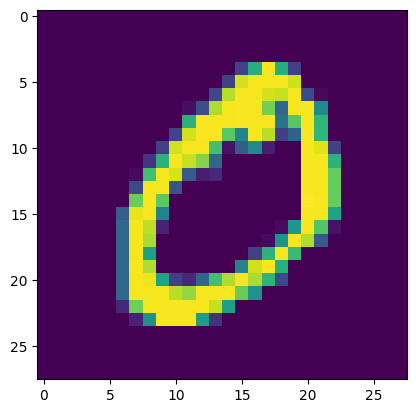

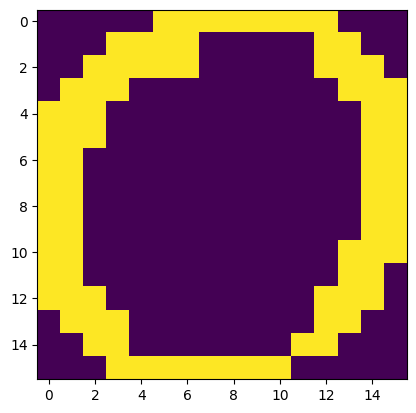

In [ ]:

ds_semeion = datasets.SEMEION(
    root="../data/SEMEION",
    download=True,
    transform=transforms.ToTensor()
) ## torchvision에서 데이터셋 로드


ds_mnist = datasets.MNIST(
    root="../data/MNIST",
    train=True,
    download=True,
    transform=transforms.ToTensor()
)

import matplotlib.pyplot as plt

plt.figure()
plt.imshow(ds_mnist[1][0].squeeze().numpy()) # MNIST DATASET 출력

plt.figure()
plt.imshow(ds_semeion[1][0].squeeze().numpy()) # SEMION DATASET 출력

In [ ]:

from torch.utils.data import random_split
import copy

semeion = datasets.SEMEION(
    root="../data/SEMEION",
    download=True,
    transform=transforms.ToTensor()
) ## torchvision에서 데이터셋 로드

train_dataset2, test_dataset2 = random_split(semeion, [0.9, 0.1]) # train dataset과 test datset으로 분할
print(len(train_dataset2))
print(len(test_dataset2))

train_loader2 = torch.utils.data.DataLoader( # data loader 정의
    dataset=train_dataset2,
    batch_size=BATCH_SIZE,
    shuffle=True
)

test_loader2 = torch.utils.data.DataLoader( # data loader 정의
    dataset=test_dataset2,
    batch_size=BATCH_SIZE,
    shuffle=False
)


def test_semion(epoch, model, criterion, optimizer): # Test 결과 출력용 재정의
    model.eval()
    test_loss = 0
    correct = 0
    total = 0
    with torch.no_grad():
        for batch_idx, (inputs, labels) in enumerate(test_loader2):
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            test_loss += loss.item()*inputs.size(0)
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

        epoch_loss = test_loss/total
        epoch_acc = correct/total*100
        print("Test | Loss:%.4f Acc: %.2f%% (%s/%s)"
            % (epoch_loss, epoch_acc, correct, total))
    return epoch_loss, epoch_acc

Files already downloaded and verified
1434
159


In [ ]:
test_loss, test_acc = test_semion(epoch, resnet_pt, criterion, optimizer)

Test | Loss:7.3531 Acc: 15.72% (25/159)


##### 손글씨 기반이라 그런지 역시 인식률이 너무 낮다
- Transfer learning으로 다시 학습해보자

In [ ]:

resnet_semion = copy.deepcopy(resnet_pt) # 테스트를 위한 Copy!!!

# freezing
for param in resnet_semion.parameters():
    param.requires_grad = True

# fc layer 수정
resnet_semion.conv1 = nn.Conv2d(1, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
resnet_semion.conv1.requires_grad = True

fc_in_features = resnet_semion.fc.in_features
resnet_semion.fc = nn.Linear(fc_in_features, 10)
resnet_semion.fc.requires_grad = True
resnet_semion = resnet_semion.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(resnet_semion.parameters(), lr=0.001,
                      momentum=0.9)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=200)


def train_semion(epoch, model, criterion, optimizer): # training을 위한 함수 재정의
    model.train()
    train_loss = 0
    correct = 0
    total = 0
    for batch_idx, (inputs, labels) in enumerate(train_loader2):
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()*inputs.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    epoch_loss = train_loss/total
    epoch_acc = correct/total*100
    print("Train | Loss:%.4f Acc: %.2f%% (%s/%s)"
        % (epoch_loss, epoch_acc, correct, total))
    return epoch_loss, epoch_acc


start_time = time.time()
best_acc = 0
epoch_length = 100
save_loss = {"train":[],
             "test":[]}
save_acc = {"train":[],
             "test":[]}
for epoch in range(epoch_length):
    print("Epoch %s" % epoch)
    train_loss, train_acc = train_semion(epoch, resnet_semion, criterion, optimizer)
    save_loss['train'].append(train_loss)
    save_acc['train'].append(train_acc)

    test_loss, test_acc = test_semion(epoch, resnet_semion, criterion, optimizer)
    save_loss['test'].append(test_loss)
    save_acc['test'].append(test_acc)

    scheduler.step()

    # Save model
    if test_acc > best_acc:
        best_acc = test_acc
        best_model_wts = copy.deepcopy(resnet_semion.state_dict())
    resnet_semion.load_state_dict(best_model_wts)

learning_time = time.time() - start_time
print(f'**Learning time: {learning_time // 60:.0f}m {learning_time % 60:.0f}s')

Epoch 0
Train | Loss:1.9533 Acc: 31.52% (452/1434)
Test | Loss:1.5664 Acc: 46.54% (74/159)
Epoch 1
Train | Loss:1.0623 Acc: 65.90% (945/1434)
Test | Loss:0.7633 Acc: 76.73% (122/159)
Epoch 2
Train | Loss:0.5463 Acc: 82.57% (1184/1434)
Test | Loss:0.5426 Acc: 83.02% (132/159)
Epoch 3
Train | Loss:0.3782 Acc: 87.45% (1254/1434)
Test | Loss:0.3526 Acc: 88.68% (141/159)
Epoch 4
Train | Loss:0.2978 Acc: 90.38% (1296/1434)
Test | Loss:0.3765 Acc: 88.05% (140/159)
Epoch 5
Train | Loss:0.2819 Acc: 91.49% (1312/1434)
Test | Loss:0.3964 Acc: 88.05% (140/159)
Epoch 6
Train | Loss:0.2871 Acc: 91.42% (1311/1434)
Test | Loss:0.3154 Acc: 88.68% (141/159)
Epoch 7
Train | Loss:0.2819 Acc: 90.86% (1303/1434)
Test | Loss:0.3961 Acc: 86.79% (138/159)
Epoch 8
Train | Loss:0.2229 Acc: 92.96% (1333/1434)
Test | Loss:0.3722 Acc: 88.05% (140/159)
Epoch 9
Train | Loss:0.2929 Acc: 90.93% (1304/1434)
Test | Loss:0.3331 Acc: 91.19% (145/159)
Epoch 10
Train | Loss:0.1855 Acc: 93.93% (1347/1434)
Test | Loss:0.3039 A



#### Pretraining되지 않았으면 어땠을까?

In [ ]:

resnet_semion = models.resnet18()

# freezing
for param in resnet_semion.parameters():
    param.requires_grad = True

# fc layer 수정
resnet_semion.conv1 = nn.Conv2d(1, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
resnet_semion.conv1.requires_grad = True

fc_in_features = resnet_semion.fc.in_features
resnet_semion.fc = nn.Linear(fc_in_features, 10)
resnet_semion.fc.requires_grad = True
resnet_semion = resnet_semion.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(resnet_semion.parameters(), lr=0.001,
                      momentum=0.9)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=200)


def train_semion(epoch, model, criterion, optimizer): # training을 위한 함수 재정의
    model.train()
    train_loss = 0
    correct = 0
    total = 0
    for batch_idx, (inputs, labels) in enumerate(train_loader2):
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()*inputs.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    epoch_loss = train_loss/total
    epoch_acc = correct/total*100
    print("Train | Loss:%.4f Acc: %.2f%% (%s/%s)"
        % (epoch_loss, epoch_acc, correct, total))
    return epoch_loss, epoch_acc


start_time = time.time()
best_acc = 0
epoch_length = 100
save_loss = {"train":[],
             "test":[]}
save_acc = {"train":[],
             "test":[]}
for epoch in range(epoch_length):
    print("Epoch %s" % epoch)
    train_loss, train_acc = train_semion(epoch, resnet_semion, criterion, optimizer)
    save_loss['train'].append(train_loss)
    save_acc['train'].append(train_acc)

    test_loss, test_acc = test_semion(epoch, resnet_semion, criterion, optimizer)
    save_loss['test'].append(test_loss)
    save_acc['test'].append(test_acc)

    scheduler.step()

    # Save model
    if test_acc > best_acc:
        best_acc = test_acc
        best_model_wts = copy.deepcopy(resnet_semion.state_dict())
    resnet_semion.load_state_dict(best_model_wts)

learning_time = time.time() - start_time
print(f'**Learning time: {learning_time // 60:.0f}m {learning_time % 60:.0f}s')

Epoch 0
Train | Loss:1.5838 Acc: 47.07% (675/1434)
Test | Loss:0.8440 Acc: 75.47% (120/159)
Epoch 1
Train | Loss:0.4401 Acc: 86.75% (1244/1434)
Test | Loss:0.4488 Acc: 87.42% (139/159)
Epoch 2
Train | Loss:0.1716 Acc: 95.75% (1373/1434)
Test | Loss:0.3495 Acc: 88.68% (141/159)
Epoch 3
Train | Loss:0.0755 Acc: 98.88% (1418/1434)
Test | Loss:0.3156 Acc: 88.05% (140/159)
Epoch 4
Train | Loss:0.0705 Acc: 98.81% (1417/1434)
Test | Loss:0.3164 Acc: 88.68% (141/159)
Epoch 5
Train | Loss:0.0770 Acc: 98.81% (1417/1434)
Test | Loss:0.3698 Acc: 87.42% (139/159)
Epoch 6
Train | Loss:0.0735 Acc: 98.68% (1415/1434)
Test | Loss:0.3424 Acc: 89.31% (142/159)
Epoch 7
Train | Loss:0.0509 Acc: 99.09% (1421/1434)
Test | Loss:0.3627 Acc: 88.68% (141/159)
Epoch 8
Train | Loss:0.0433 Acc: 99.51% (1427/1434)
Test | Loss:0.3648 Acc: 88.68% (141/159)
Epoch 9
Train | Loss:0.0422 Acc: 99.23% (1423/1434)
Test | Loss:0.3480 Acc: 89.94% (143/159)
Epoch 10
Train | Loss:0.0460 Acc: 98.88% (1418/1434)
Test | Loss:0.3084

#### 마지막으로 가지고 있는 데이터로 yolo trasfer learning을 해보자
- 라벨링한 데이터를 content/dataset/train/images/ 경로에 저장
- /content/yolov5/models/yolo5s.yaml 열기
- line 4 nc 수정(class 개수로)

##### 저장 경로 이미지 리스트 불러오기

In [ ]:
from glob import glob

img_list = glob('/content/dataset/train/images/*.jpg')

print(len(img_list))

0


##### training data와 test data 분류

In [ ]:
from sklearn.model_selection import train_test_split
train_img_list, val_img_list = train_test_split(img_list, test_size=0.2, random_state=2000)

print(len(train_img_list), len(val_img_list))

##### 분류한 train, test 데이터 리스트 저장

In [ ]:
with open('/content/dataset/train.txt', 'w') as f:
  f.write('\n'.join(train_img_list) + '\n')

with open('/content/dataset/val.txt', 'w') as f:
  f.write('\n'.join(val_img_list) + '\n')

##### dataset 리스트 만들기(data.yaml)

In [ ]:
with open('/content/dataset/data.yaml', 'r') as f:
  data = yaml.load(f)

print(data)

data['train'] = '/content/dataset/train.txt'
data['val'] = '/content/dataset/val.txt'

with open('/content/dataset/data.yaml', 'w') as f:
  yaml.dump(data, f)

print(data)

##### dataset 학습

In [ ]:
%cd /content/yolov5/

!python train.py --img 416 --batch 16 --epochs 50 --data /content/dataset/data.yaml --cfg ./models/yolov5s.yaml --weights yolov5s.pt --name yolov5s_results

/content/yolov5
train: weights=yolov5s.pt, cfg=./models/yolov5s.yaml, data=/content/dataset/data.yaml, hyp=data/hyps/hyp.scratch-low.yaml, epochs=50, batch_size=16, imgsz=416, rect=False, resume=False, nosave=False, noval=False, noautoanchor=False, noplots=False, evolve=None, bucket=, cache=None, image_weights=False, device=, multi_scale=False, single_cls=False, optimizer=SGD, sync_bn=False, workers=8, project=runs/train, name=yolov5s_results, exist_ok=False, quad=False, cos_lr=False, label_smoothing=0.0, patience=100, freeze=[0], save_period=-1, seed=0, local_rank=-1, entity=None, upload_dataset=False, bbox_interval=-1, artifact_alias=latest
github: up to date with https://github.com/ultralytics/yolov5 ✅
Traceback (most recent call last):
  File "/content/yolov5/train.py", line 647, in <module>
    main(opt)
  File "/content/yolov5/train.py", line 511, in main
    check_file(opt.data), check_yaml(opt.cfg), check_yaml(opt.hyp), str(opt.weights), str(opt.project)  # checks
  File "/cont

##### 결과 확인
- image 입력후 결과 확인

In [ ]:
import os
import time
from PIL import Image, ImageDraw
import cv2
import numpy as np

# 동작시킬 이미지 url
url = "https://content.gallup.com/origin/gallupinc/GallupSpaces/Production/Cms/TGBCMS/iy1ex3cookmf9cme5qlnxa.jpg"

# time check
start = time.time()

# curl 요청
os.system("curl " + url + " > test.jpg")

# 이미지 다운로드 시간 체크
print(time.time() - start)

# 저장 된 이미지 확인
img = Image.open("test.jpg")

results = model(img)
results.print()
results.show()

In [ ]:
!python detect.py --weights '/content/yolov5/runs/train/yolov5s_results/weights/best.pt' --img 1280 --conf 0.4 --source '/content/drive/MyDrive/Colab_Notebooks/160-2_cam01_dump02_place10_day_spring.mp4'